In [1]:
!pip -q install "pypdf>=4.0" faiss-cpu "sentence-transformers>=3.0" "accelerate>=0.30" pydantic

In [2]:
import os, re, json, time, hashlib, gc, math, warnings, textwrap, platform
from pathlib import Path
from collections import Counter, defaultdict, OrderedDict
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)

COUNTRY = "Latvia"
COUNTRY_HEADER = "REPUBLIC OF LATVIA"
REPORT_TITLE = "Republic of Latvia: 2024 Article IV Consultation-Press Release; and Staff Report"
REPORT_ID = "IMF Country Report No. 24/284"
REPORT_YEAR = 2024
PDF_URLS = [
    "https://www.elibrary.imf.org/downloadpdf/view/journals/002/2024/284/002.2024.issue-284-en.pdf",
    "https://www.imf.org/-/media/files/publications/cr/2024/english/1lvaea2024001.pdf",
    "https://www.imf.org/-/media/Files/Publications/CR/2024/English/1LVAEA2024001.ashx",
]

USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/imf_latvia_pipeline")
else:
    BASE_DIR = Path(os.environ.get("PIPELINE_DIR", "imf_latvia_pipeline")).resolve()

DATA_DIR, OUT_DIR, FIG_DIR, CACHE_DIR = (BASE_DIR / d for d in ("data", "outputs", "figures", "cache"))
for d in (DATA_DIR, OUT_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
PDF_PATH = DATA_DIR / "latvia_2024_article_iv_staff_report.pdf"

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    EXTRACTOR_MODEL = "Qwen/Qwen2.5-3B-Instruct"
    JUDGE_MODEL = "microsoft/Phi-3.5-mini-instruct"
else:
    EXTRACTOR_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
    JUDGE_MODEL = "HuggingFaceTB/SmolLM2-360M-Instruct"
    print("⚠ No GPU detected – using small CPU models. Switch to a T4 runtime for report-quality results.")
EMBED_MODEL = "BAAI/bge-small-en-v1.5"
BGE_QUERY_PREFIX = "Represent this sentence for searching relevant passages: "

CHUNK_TOKENS = 350
CHUNK_OVERLAP = 50
EXTRACTOR_MAX_INPUT_TOKENS = 3500
JUDGE_MAX_SOURCE_TOKENS = 2800
SUMMARY_WORD_LIMIT = 100
TOP_K = 4
PROMPT_VERSION = "latvia"
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

print(f"Python {platform.python_version()} | torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0) if HAS_GPU else 'none'}")
print("Working directory:", BASE_DIR)

Python 3.13.16 | torch 2.11.0+cu130 | GPU: Tesla T4
Working directory: /content/imf_latvia_pipeline


In [3]:
def _json_default(o):
    """Make numpy / pandas objects JSON-serialisable and turn NaN into null."""
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, Path): return str(o)
    return str(o)

def _nan_to_none(obj):
    if isinstance(obj, float) and math.isnan(obj): return None
    if isinstance(obj, dict): return {k: _nan_to_none(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)): return [_nan_to_none(v) for v in obj]
    return obj

def save_json(obj, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(_nan_to_none(obj), indent=2, ensure_ascii=False, default=_json_default))
    return path

def load_json(path: Path, default=None):
    try:
        return json.loads(Path(path).read_text())
    except Exception:
        return default

def stable_hash(obj) -> str:
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()[:24]

def word_count(text: str) -> int:
    return len(re.findall(r"[A-Za-z0-9][\w'’%.,/-]*", text or ""))

def _balanced_span(text: str, start: int) -> Optional[str]:
    """Return the balanced {...} or [...] substring starting at `start`, honouring JSON strings."""
    open_ch = text[start]; close_ch = "}" if open_ch == "{" else "]"
    depth, in_str, esc = 0, False, False
    for i in range(start, len(text)):
        ch = text[i]
        if in_str:
            if esc: esc = False
            elif ch == "\\": esc = True
            elif ch == '"': in_str = False
            continue
        if ch == '"': in_str = True
        elif ch == open_ch: depth += 1
        elif ch == close_ch:
            depth -= 1
            if depth == 0: return text[start:i + 1]
    return None

def parse_json_block(text: str, expect=("{", "[")):
    """Extract the first valid JSON object/array from free-form model output (None if impossible)."""
    if not text: return None
    t = re.sub(r"```(?:json)?", "", text).replace("“", '"').replace("”", '"').replace("’", "'")
    for m in re.finditer(r"[\{\[]", t):
        if m.group() not in expect: continue
        span = _balanced_span(t, m.start())
        if not span: continue
        for candidate in (span, re.sub(r",\s*([\}\]])", r"\1", span)):
            try:
                return json.loads(candidate)
            except Exception:
                continue
    return None

def to_float(x) -> Optional[float]:
    """Coerce '2.4', '2.4%', '−0.3' or 2.4 to float; return None for null / unparsable values."""
    if x is None or isinstance(x, bool): return None
    if isinstance(x, (int, float)): return None if (isinstance(x, float) and math.isnan(x)) else float(x)
    m = re.search(r"[-−–]?\d+(?:\.\d+)?", str(x))
    return float(m.group().replace("−", "-").replace("–", "-")) if m else None

def number_in_text(value, text) -> bool:
    """True if the value appears as a number token in the text (2.4 matches '2.4', 20.2 does not match '120.2')."""
    if value is None: return False
    variants = {f"{value:g}", f"{value:.1f}", f"{value:.2f}", str(int(value)) if float(value).is_integer() else f"{value:g}"}
    norm = text.replace("−", "-").replace("–", "-")
    return any(re.search(rf"(?<![\d.]){re.escape(v)}(?!\d|\.\d)", norm) for v in variants)

Utilities ready.


Local LLM with disk cache

In [4]:
class LocalLLM:
    """Thin, cached wrapper around a Hugging Face chat model running inside the runtime (no API keys)."""
    _active = None

    def __init__(self, model_id: str, role: str, dtype=None):
        self.model_id, self.role = model_id, role
        self.dtype = dtype or (torch.float16 if HAS_GPU else torch.float32)
        self.model = self.tok = None
        self.cache_dir = CACHE_DIR / "llm" / re.sub(r"[^\w.-]", "_", model_id)
        self.cache_dir.mkdir(parents=True, exist_ok=True)
        self.calls = {"cached": 0, "generated": 0}

    def _load(self, dtype):
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.tok = AutoTokenizer.from_pretrained(self.model_id)
        kwargs = {"torch_dtype": dtype}
        if HAS_GPU: kwargs["device_map"] = "cuda"
        self.model = AutoModelForCausalLM.from_pretrained(self.model_id, **kwargs).eval()

    def _ensure_loaded(self):
        if self.model is not None: return
        if LocalLLM._active is not None and LocalLLM._active is not self:
            LocalLLM._active.unload()
        t0 = time.time()
        print(f"Loading {self.role} model {self.model_id} ({self.dtype}) …")
        self._load(self.dtype)
        LocalLLM._active = self
        if not self._healthy() and self.dtype == torch.float16:
            print("  fp16 output looked degenerate → reloading in fp32")
            self.unload(); self.dtype = torch.float32; self._load(self.dtype); LocalLLM._active = self
        print(f"  loaded in {time.time() - t0:.0f}s")

    def _healthy(self) -> bool:
        out = self._raw_generate(None, "Reply with the single word: ready", 8)
        return bool(re.search(r"[A-Za-z]{3,}", out["text"]))

    def unload(self):
        if self.model is None: return
        print(f"Unloading {self.role} model {self.model_id}")
        self.model = None; self.tok = None
        if LocalLLM._active is self: LocalLLM._active = None
        gc.collect()
        if HAS_GPU: torch.cuda.empty_cache()

    def _chat_prompt(self, system, user):
        msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": user}]
        try:
            return self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        except Exception:
            merged = [{"role": "user", "content": (system + "\n\n" if system else "") + user}]
            return self.tok.apply_chat_template(merged, tokenize=False, add_generation_prompt=True)

    def _raw_generate(self, system, user, max_new_tokens):
        prompt = self._chat_prompt(system, user)
        inputs = self.tok(prompt, return_tensors="pt").to(self.model.device)
        n_in = int(inputs["input_ids"].shape[1])
        t0 = time.perf_counter()
        with torch.inference_mode():
            out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                      temperature=None, top_p=None, top_k=None, repetition_penalty=1.05,
                                      pad_token_id=self.tok.pad_token_id or self.tok.eos_token_id)
        latency = time.perf_counter() - t0
        text = self.tok.decode(out[0, n_in:], skip_special_tokens=True).strip()
        return {"text": text, "latency_s": round(latency, 3), "n_in": n_in, "n_out": int(out.shape[1] - n_in)}

    def generate(self, user: str, system: Optional[str] = None, max_new_tokens: int = 256, tag: str = "") -> dict:
        key = stable_hash([self.model_id, system, user, max_new_tokens, PROMPT_VERSION])
        path = self.cache_dir / f"{key}.json"
        cached = load_json(path)
        if cached is not None:
            self.calls["cached"] += 1
            return {**cached, "cached": True}
        self._ensure_loaded()
        try:
            rec = self._raw_generate(system, user, max_new_tokens)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print("  CUDA OOM – retrying with the prompt shortened to 70%")
            rec = self._raw_generate(system, user[: int(len(user) * 0.7)], max_new_tokens)
        rec.update({"model": self.model_id, "role": self.role, "tag": tag, "prompt_key": key})
        save_json(rec, path)
        self.calls["generated"] += 1
        return {**rec, "cached": False}

extractor = LocalLLM(EXTRACTOR_MODEL, role="extractor")
judge = LocalLLM(JUDGE_MODEL, role="judge")
print("Extractor:", EXTRACTOR_MODEL, "| Judge:", JUDGE_MODEL, "| cache:", CACHE_DIR / "llm")

Extractor: Qwen/Qwen2.5-3B-Instruct | Judge: microsoft/Phi-3.5-mini-instruct | cache: /content/imf_latvia_pipeline/cache/llm


Load Report

In [5]:
import requests
from pypdf import PdfReader

def acquire_pdf(path: Path, urls) -> Path:
    """Return a local path to the report PDF: cached file → IMF download → manual Colab upload."""
    if path.exists() and path.read_bytes()[:4] == b"%PDF":
        return path
    for folder in (Path.cwd(), Path("/content"), BASE_DIR):
        for cand in sorted(folder.glob("*284*.pdf")) + sorted(folder.glob("*1lvaea2024*.pdf")):
            if cand.read_bytes()[:4] == b"%PDF":
                path.write_bytes(cand.read_bytes()); print("Using local copy:", cand); return path
    for url in urls:
        try:
            r = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (academic text-mining pipeline)"}, timeout=60)
            if r.ok and r.content[:4] == b"%PDF":
                path.write_bytes(r.content); print("Downloaded from", url); return path
            print(f"Download attempt returned HTTP {r.status_code} / non-PDF content: {url}")
        except Exception as e:
            print(f"Download failed ({type(e).__name__}): {url}")
    try:
        from google.colab import files
        print("Please upload the IMF PDF (Country Report No. 24/284) – the IMF site blocked the scripted download.")
        uploaded = files.upload()
        name = next(iter(uploaded))
        data = uploaded[name]
        if not data.startswith(b"%PDF"):
            raise ValueError("Uploaded file is not a PDF. Please use IMF Country Report 24/284.")
        path.write_bytes(data)
        return path
    except ImportError:
        raise FileNotFoundError(f"Place the report PDF at {path} and re-run this cell.")

PDF_PATH = acquire_pdf(PDF_PATH, PDF_URLS)
pdf_sha = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
reader = PdfReader(str(PDF_PATH))
raw_pages = [(p.extract_text() or "") for p in reader.pages]
print(f"{PDF_PATH.name}: {len(raw_pages)} pages, {sum(len(p) for p in raw_pages):,} raw characters, sha256={pdf_sha[:16]}…")

Download attempt returned HTTP 202 / non-PDF content: https://www.elibrary.imf.org/downloadpdf/view/journals/002/2024/284/002.2024.issue-284-en.pdf
Download attempt returned HTTP 403 / non-PDF content: https://www.imf.org/-/media/files/publications/cr/2024/english/1lvaea2024001.pdf
Download attempt returned HTTP 403 / non-PDF content: https://www.imf.org/-/media/Files/Publications/CR/2024/English/1LVAEA2024001.ashx
Please upload the IMF PDF (Country Report No. 24/284) – the IMF site blocked the scripted download.


Saving 1934-7685-002.2024.issue-284-en.pdf to 1934-7685-002.2024.issue-284-en.pdf
latvia_2024_article_iv_staff_report.pdf: 80 pages, 197,766 raw characters, sha256=923bb1dbf40b65c3…


In [6]:
NUM_TOKEN = re.compile(r"^[-−–]?\(?\d+(?:[.,]\d+)?\)?%?\.?$|^…$|^\.\.\.$")
YEAR_TOKEN = re.compile(r"^(?:19|20)\d{2}$")
NOISE_LINE = [
    re.compile(r"^(?:19|20)\d{2}(?:Q[1-4]|M\d{1,2})?$"),
    re.compile(r"^(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)-?\d{2,4}$"),
    re.compile(r"^(?:Q[1-4]|H[12])(?:[- ]\d{2,4})?$"),
    re.compile(r"^[_\W\d]{0,3}$"),
    re.compile(r"_{3,}"),
    re.compile(r"^Proj\.?$|^Projections?$"),
]
HEADER_PATTERNS = [
    re.compile(rf"^{re.escape(COUNTRY_HEADER)}$", re.I),
    re.compile(r"^\d*\s*INTERNATIONAL MONETARY FUND\s*\d*$", re.I),
    re.compile(r"^©\s*\d{4}\s+International Monetary Fund", re.I),
]

def is_year_header(tokens) -> bool:
    years = [int(t) for t in tokens if YEAR_TOKEN.match(t)]
    return len(years) >= 4 and len(years) >= 0.7 * len(tokens) and all(b - a == 1 for a, b in zip(years, years[1:]))

def is_noise(line: str) -> bool:
    tokens = line.split()
    if not tokens: return True
    if is_year_header(tokens): return False
    if all(NUM_TOKEN.match(t) or YEAR_TOKEN.match(t) for t in tokens): return True
    return any(p.search(line) for p in NOISE_LINE)

def detect_boilerplate(pages, min_share=0.25):
    """Short lines repeated on many pages (after normalising digits) are running headers/footers."""
    counts = Counter()
    for page in pages:
        counts.update({re.sub(r"\d+", "#", l.strip()) for l in page.splitlines() if 0 < len(l.strip()) < 70})
    threshold = max(3, int(min_share * len(pages)))
    return {line for line, c in counts.items() if c >= threshold}

def clean_pages(pages):
    """Return [(page_no, line)] after removing headers, footers and chart artefacts."""
    boiler = detect_boilerplate(pages)
    stats = Counter(); out = []
    for pno, page in enumerate(pages, start=1):
        for raw in page.splitlines():
            line = re.sub(r"\s+", " ", raw.replace(" ", " ")).strip()
            if not line: continue
            if any(p.search(line) for p in HEADER_PATTERNS) or re.sub(r"\d+", "#", line) in boiler:
                stats["header/footer"] += 1; continue
            if is_noise(line):
                stats["chart/axis noise"] += 1; continue
            if out and out[-1][1].endswith("-") and re.match(r"^[a-z]", line):
                out[-1] = (out[-1][0], out[-1][1] + line); stats["hyphen joins"] += 1; continue
            out.append((pno, line))
    return out, stats

clean_lines, clean_stats = clean_pages(raw_pages)
print(f"Kept {len(clean_lines):,} lines | removed: {dict(clean_stats)}")
mid = len(clean_lines) // 2
print("\nSample cleaned lines:", *[f"  p{p}: {l}" for p, l in clean_lines[mid:mid + 6]], sep="\n")

Kept 3,251 lines | removed: {'header/footer': 1457, 'chart/axis noise': 561, 'hyphen joins': 21}

Sample cleaned lines:
  p43: Core, period average 2.7 1.1 2.0 11.3 9.8 3.3 3.1
  p43: Core, end-period 1.9 0.9 4.7 15.2 4.0 3.7 2.8
  p43: Labor Market
  p43: Unemployment rate (LFS; period average, percent) 6.3 8.1 7.6 6.9 6.5 6. 5 6.5
  p43: Nominal wage growth 7.2 6.2 11.7 7.5 11.9 8.5 7.0
  p43: Consolidated General Government 1/


In [7]:
SECTION_SPECS = [
    ("Press Release",                    r"^IMF Executive Board Concludes"),
    ("Executive Board Assessment",       r"^Executive Board Assessment"),
    ("Key Issues",                       r"^KEY ISSUES$"),
    ("Context",                          r"^CONTEXT$"),
    ("Recent Developments",              r"^RECENT DEVELOPMENTS$"),
    ("Outlook and Risks",                r"^OUTLOOK AND RISKS$"),
    ("Policy Discussions: Fiscal",       r"^A\.\s+Fiscal Policy"),
    ("Policy Discussions: Financial Sector", r"^B\.\s+Financial Sector"),
    ("Policy Discussions: Structural",   r"^C\.\s+Structural"),
    ("Staff Appraisal",                  r"^STAFF APPRAISAL$"),
    ("Figures and Statistical Tables",   r"^Figure\s+\d+\.\s+\S"),
]
ANNEX_RE = re.compile(r"^Annex\s+([IVX]+)\.\s+(?!Figure|Table)(.{3,80})$")
INFO_ANNEX_RE = re.compile(r"INFORMATIONAL ANNEX$")

def detect_sections(lines):
    """Return a list of section dicts {name, start, end} (indices into `lines`)."""
    starts, pos = [], 0
    for name, pat in SECTION_SPECS:
        rx = re.compile(pat)
        for i in range(pos, len(lines)):
            if rx.search(lines[i][1]):
                starts.append((i, name)); pos = i + 1; break
    seen = set()
    for i in range(pos, len(lines)):
        m = ANNEX_RE.match(lines[i][1])
        if m and m.group(1) not in seen:
            title = re.sub(r"\d+$", "", m.group(2).strip())
            seen.add(m.group(1)); starts.append((i, f"Annex {m.group(1)}: {title}"))
        elif INFO_ANNEX_RE.search(lines[i][1]) and "info" not in seen:
            seen.add("info"); starts.append((i, "Informational Annex"))
    starts.sort()
    if len(starts) < 3:
        step = max(1, len(lines) // 12)
        starts = [(i, f"Part {k + 1}") for k, i in enumerate(range(0, len(lines), step))]
    if starts[0][0] > 0:
        starts.insert(0, (0, "Front Matter"))
    sections = []
    for k, (i, name) in enumerate(starts):
        end = starts[k + 1][0] if k + 1 < len(starts) else len(lines)
        sections.append({"name": name, "start": i, "end": end})
    return sections

def assemble_text(lines_slice):
    """Join lines into flowing text and record the character offset where each page starts."""
    text_parts, offsets, cursor = [], [], 0
    for pno, line in lines_slice:
        offsets.append((cursor, pno))
        text_parts.append(line); cursor += len(line) + 1
    raw = "\n".join(text_parts)
    flowing = re.sub(r"(?<![.:;!?])\n(?!•)", " ", raw)
    return flowing, offsets

sections = detect_sections(clean_lines)
for s in sections:
    s["text"], s["page_offsets"] = assemble_text(clean_lines[s["start"]:s["end"]])
    s["pages"] = (clean_lines[s["start"]][0], clean_lines[s["end"] - 1][0])
    s["words"] = word_count(s["text"])
full_text = "\n\n".join(s["text"] for s in sections)

sec_df = pd.DataFrame([{"section": s["name"], "pages": f"{s['pages'][0]}–{s['pages'][1]}", "words": s["words"]} for s in sections])
display(sec_df)
print(f"Total cleaned words: {word_count(full_text):,}")

,section,pages,words
0,Front Matter,2–3,210
1,Press Release,3–3,336
2,Executive Board Assessment,3–7,1359
3,Key Issues,7–10,491
4,Context,11–12,471
5,Recent Developments,12–16,1308
6,Outlook and Risks,16–18,1135
7,Policy Discussions: Fiscal,19–24,2437
8,Policy Discussions: Financial Sector,24–26,1093
9,Policy Discussions: Structural,27–32,2242


Total cleaned words: 26,172


In [8]:
from sentence_transformers import SentenceTransformer
import faiss

embedder = SentenceTransformer(EMBED_MODEL, device="cuda" if HAS_GPU else "cpu")
emb_tok = embedder.tokenizer

def n_tokens(texts):
    if isinstance(texts, str): texts = [texts]
    return [len(ids) for ids in emb_tok(list(texts), add_special_tokens=False)["input_ids"]]

SENT_BOUNDARY = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9(•“\"])|\n+")

def sentence_spans(text):
    spans, start = [], 0
    for m in SENT_BOUNDARY.finditer(text):
        if text[start:m.start()].strip(): spans.append((start, m.start()))
        start = m.end()
    if text[start:].strip(): spans.append((start, len(text)))
    return spans

def page_at(offset, page_offsets):
    page = page_offsets[0][1]
    for off, pno in page_offsets:
        if off > offset: break
        page = pno
    return page

def chunk_section(sec, max_tokens=CHUNK_TOKENS, overlap=CHUNK_OVERLAP):
    text = sec["text"]
    spans = sentence_spans(text)
    sents = [text[a:b].strip() for a, b in spans]
    counts = n_tokens(sents) if sents else []
    units = []
    for (a, _), s, c in zip(spans, sents, counts):
        if c <= max_tokens:
            units.append((a, s, c)); continue
        words = s.split(); step = max(10, int(len(words) * max_tokens / c * 0.9))
        w = 0
        while w < len(words):
            take = step
            while True:
                piece = " ".join(words[w:w + take]); t = n_tokens(piece)[0]
                if t <= max_tokens or take <= 10: break
                take = int(take * 0.85)
            units.append((a, piece, t)); w += take
    chunks, cur, cur_tok = [], [], 0
    def flush():
        if cur:
            chunks.append({"section": sec["name"], "page": page_at(cur[0][0], sec["page_offsets"]),
                           "text": " ".join(u[1] for u in cur), "n_tokens": sum(u[2] for u in cur)})
    for u in units:
        if cur and cur_tok + u[2] > max_tokens:
            flush()
            carry, carry_tok = [], 0
            for prev in reversed(cur):
                if carry_tok >= overlap or carry_tok + prev[2] > max_tokens // 2: break
                carry.insert(0, prev); carry_tok += prev[2]
            if carry_tok + u[2] > max_tokens:
                carry, carry_tok = [], 0
            cur, cur_tok = carry, carry_tok
        cur.append(u); cur_tok += u[2]
    flush()
    return chunks

chunks = []
for sec in sections:
    for c in chunk_section(sec):
        c["id"] = len(chunks); chunks.append(c)
chunk_df = pd.DataFrame(chunks)
print(f"{len(chunks)} chunks | tokens: mean {chunk_df.n_tokens.mean():.0f}, max {chunk_df.n_tokens.max()}, min {chunk_df.n_tokens.min()}")
display(chunk_df.groupby("section", sort=False).size().rename("chunks").to_frame().T)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (943 > 512). Running this sequence through the model will result in indexing errors


156 chunks | tokens: mean 303, max 350, min 67


section,Front Matter,Press Release,Executive Board Assessment,Key Issues,Context,Recent Developments,Outlook and Risks,Policy Discussions: Fiscal,Policy Discussions: Financial Sector,Policy Discussions: Structural,...,Figures and Statistical Tables,Annex I: Risk Assessment Matrix,Annex II: External Sector Assessment,Annex III: Sovereign Risk and Debt Sustainability Analysis,Annex IV: Productivity in the Baltic Context,Annex V: Selected Measures to Address Labor Shortages,Annex VI: Data Issues,Annex VII: Past IMF Policy Recommendations,Annex VIII: Rail Baltica,Informational Annex
chunks,1,2,8,3,3,7,7,13,6,12,...,28,6,4,15,11,4,7,2,7,6


In [9]:
def build_or_load_index(chunks):
    """Embed chunks once (cached on disk by content hash) and build an exact FAISS L2 index."""
    key = stable_hash([EMBED_MODEL, [c["text"] for c in chunks]])
    emb_path = CACHE_DIR / f"embeddings_{key}.npy"
    if emb_path.exists():
        vecs = np.load(emb_path); print("Loaded cached embeddings", vecs.shape)
    else:
        vecs = embedder.encode([c["text"] for c in chunks], batch_size=32, normalize_embeddings=True,
                               show_progress_bar=True).astype("float32")
        np.save(emb_path, vecs)
    index = faiss.IndexFlatL2(vecs.shape[1])
    index.add(vecs)
    return index, vecs

index, chunk_vecs = build_or_load_index(chunks)

def embed_queries(queries):
    return embedder.encode([BGE_QUERY_PREFIX + q for q in queries], normalize_embeddings=True).astype("float32")

def retrieve(query: str, k: int = TOP_K, sections_filter=None):
    """Dense retrieval; returns chunk dicts with a cosine `score`."""
    D, I = index.search(embed_queries([query]), min(len(chunks), k * 4 if sections_filter else k))
    hits = []
    for d, i in zip(D[0], I[0]):
        c = chunks[int(i)]
        if sections_filter and not any(f.lower() in c["section"].lower() for f in sections_filter): continue
        hits.append({**c, "score": float(1 - d / 2)})
        if len(hits) == k: break
    return hits

def format_context(hits, max_tokens=EXTRACTOR_MAX_INPUT_TOKENS):
    """Render retrieved chunks with citable ids, stopping at the token budget."""
    blocks, used = [], 0
    for h in hits:
        block = f"[C{h['id']} | p.{h['page']} | {h['section']}]\n{h['text']}"
        t = n_tokens(block)[0]
        if used + t > max_tokens: break
        blocks.append(block); used += t
    return "\n\n".join(blocks)

def truncate_tokens(text, max_tokens):
    t = n_tokens(text)[0]
    return text if t <= max_tokens else text[: int(len(text) * max_tokens / t * 0.95)] + " …[truncated]"

demo = retrieve("countercyclical capital buffer requirement")
print("Top hit:", f"C{demo[0]['id']} p.{demo[0]['page']} ({demo[0]['section']}) score={demo[0]['score']:.3f}")
print(textwrap.shorten(demo[0]["text"], 300))

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Top hit: C44 p.24 (Policy Discussions: Financial Sector) score=0.690
B. Financial Sector Policies: Balancing Risks and Resilience 27. Given heightened risks, continued monitoring of financial sector vulnerabilities and macrofinancial spillovers is warranted. • A regular risk-based monitoring of banks’ asset quality supported by tailored stress testing should [...]


Section Summaries & Excutive Summary

In [10]:
SUMMARY_SYSTEM = """You are an IMF macro-financial analyst writing for a financial-stability committee.
You summarise ONE section of an IMF Article IV staff report.
Rules:
1. Use ONLY facts stated in the SOURCE. Do not add outside knowledge, dates or numbers.
2. Copy every number exactly as written in the SOURCE, with its unit and year.
3. Output ONE plain paragraph of at most {limit} words. No headings, no bullet points, no preamble such as "This section".
4. Order: main finding, then the key figures, then the IMF staff recommendation (if the SOURCE gives one)."""

NOTES_SYSTEM = """You condense part of an IMF report into factual notes for a later summary.
Use ONLY the SOURCE. Keep every key number with its unit and year. At most 120 words, plain sentences."""

REPAIR_PROMPT = """The summary below has {n} words but must have FEWER than {limit} words.
Rewrite it in at most {target} words. Keep the most important numbers exactly as written. Output only the rewritten paragraph.

SUMMARY:
{summary}"""

SKIP_SUMMARY = {"Front Matter"}

def split_for_budget(text, budget=EXTRACTOR_MAX_INPUT_TOKENS):
    spans = sentence_spans(text); sents = [text[a:b].strip() for a, b in spans]
    parts, cur, cur_t = [], [], 0
    for s, t in zip(sents, n_tokens(sents) if sents else []):
        if cur and cur_t + t > budget:
            parts.append(" ".join(cur)); cur, cur_t = [], 0
        cur.append(s); cur_t += t
    if cur: parts.append(" ".join(cur))
    return parts

def enforce_word_limit(summary, limit=SUMMARY_WORD_LIMIT, max_attempts=2):
    attempts = 0
    while word_count(summary) >= limit and attempts < max_attempts:
        attempts += 1
        target = int(limit * (0.8 - 0.1 * attempts))
        summary = extractor.generate(REPAIR_PROMPT.format(n=word_count(summary), limit=limit, target=target,
                                                         summary=summary), max_new_tokens=180, tag="repair")["text"]
    if word_count(summary) >= limit:
        words = summary.split()[: limit - 1]
        summary = " ".join(words).rsplit(".", 1)[0] + "."
        attempts += 1
    return summary.strip(), attempts

def summarise_section(sec):
    parts = split_for_budget(sec["text"])
    latency = 0.0
    if len(parts) > 1:
        notes = []
        for p in parts:
            r = extractor.generate(f"SOURCE ({sec['name']}):\n{p}", system=NOTES_SYSTEM, max_new_tokens=200, tag="map")
            notes.append(r["text"]); latency += r["latency_s"]
        source_for_summary = "\n".join(notes)
    else:
        source_for_summary = parts[0] if parts else sec["text"]
    r = extractor.generate(f"SECTION: {sec['name']}\nSOURCE:\n{source_for_summary}",
                           system=SUMMARY_SYSTEM.format(limit=85), max_new_tokens=200, tag="summary")
    latency += r["latency_s"]
    raw_words = word_count(r["text"])
    final, repairs = enforce_word_limit(r["text"])
    return {"section": sec["name"], "pages": sec["pages"], "summary": final, "words": word_count(final),
            "first_draft_words": raw_words, "repairs": repairs, "map_parts": len(parts), "latency_s": round(latency, 2)}

section_summaries = []
for sec in sections:
    if sec["name"] in SKIP_SUMMARY or sec["words"] < 40: continue
    section_summaries.append(summarise_section(sec))
    s = section_summaries[-1]
    print(f"✓ {s['section']:<42} {s['words']:>3} words (draft {s['first_draft_words']}, repairs {s['repairs']}, map parts {s['map_parts']})")
save_json(section_summaries, OUT_DIR / "section_summaries.json")

Loading extractor model Qwen/Qwen2.5-3B-Instruct (torch.float16) …


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  loaded in 27s
✓ Press Release                               66 words (draft 66, repairs 0, map parts 1)
✓ Executive Board Assessment                  84 words (draft 84, repairs 0, map parts 1)
✓ Key Issues                                  66 words (draft 66, repairs 0, map parts 1)
✓ Context                                     90 words (draft 90, repairs 0, map parts 1)
✓ Recent Developments                         68 words (draft 68, repairs 0, map parts 1)
✓ Outlook and Risks                           60 words (draft 60, repairs 0, map parts 1)
✓ Policy Discussions: Fiscal                  55 words (draft 55, repairs 0, map parts 1)
✓ Policy Discussions: Financial Sector        72 words (draft 72, repairs 0, map parts 1)
✓ Policy Discussions: Structural              88 words (draft 88, repairs 0, map parts 1)
✓ Staff Appraisal                             91 words (draft 91, repairs 0, map parts 1)
✓ Figures and Statistical Tables              99 words (draft 113, repairs 2, map pa

PosixPath('/content/imf_latvia_pipeline/outputs/section_summaries.json')

In [11]:
EXEC_TOPICS = OrderedDict([
    ("Growth outlook", "real GDP growth contracted in 2023 and is projected to rebound in 2024 and 2025"),
    ("Inflation", "headline and core inflation declined, inflation outlook and services inflation"),
    ("Banking sector", "banking sector well capitalized liquid low NPL ratio resilient"),
    ("Credit and housing", "credit risk variable interest rate loans households corporates house prices"),
    ("Public finances", "fiscal deficit public debt to GDP fiscal stance recommendation 2024 2025"),
    ("Macroprudential policy", "countercyclical capital buffer borrower-based measures macroprudential stance"),
    ("Main risks", "downside risks geopolitical tensions fragmentation external demand competitiveness"),
    ("Structural reforms", "structural reforms productivity skilled labor shortages investment"),
])
EXEC_SYSTEM = """You write ONE bullet point for the executive summary of an IMF Article IV report on {country}.
Topic: {topic}.
Rules: use ONLY the EVIDENCE; copy every number exactly and state the year it refers to; at most 30 words;
end the bullet with the id of the chunk you used, e.g. [C12]. Output only the bullet text."""

def cited_ids(text):
    """Chunk ids cited as [C12], [C12, C13] or [C12][C13]."""
    return [int(x) for group in re.findall(r"\[([^\]]*)\]", text) for x in re.findall(r"C\s*(\d+)", group)]

def write_bullet(topic, query):
    hits = retrieve(query, k=3)
    ctx = format_context(hits, max_tokens=1300)
    shown = {h["id"] for h in hits}
    bullet, ok, ids = "", False, []
    for attempt in range(2):
        extra = "" if attempt == 0 else "\nYour previous bullet used a number or citation not found in the EVIDENCE. Use only figures written in the cited chunk."
        r = extractor.generate(f"EVIDENCE:\n{ctx}{extra}", system=EXEC_SYSTEM.format(country=COUNTRY, topic=topic),
                               max_new_tokens=90, tag="exec_bullet")
        bullet = re.sub(r"^\s*(?:[-•*]|\d+[.)])\s*", "", r["text"].strip().splitlines()[0] if r["text"].strip() else "")
        ids = [i for i in cited_ids(bullet) if i in shown]
        source = " ".join(h["text"] for h in hits)
        nums = re.findall(r"(?<![\w.])-?\d+(?:\.\d+)?", re.sub(r"\[[^\]]*\]", "", bullet))
        ok = bool(ids) and all(number_in_text(float(n), source) for n in nums) and 4 <= word_count(bullet) <= 40
        if ok: break
    return {"topic": topic, "bullet": bullet, "evidence_ids": ids, "deterministic_check": ok, "attempts": attempt + 1}

exec_rows = [write_bullet(t, q) for t, q in EXEC_TOPICS.items()]
exec_bullets = [r["bullet"] for r in exec_rows if r["deterministic_check"]]
exec_summary = {"bullets": exec_bullets, "n_bullets": len(exec_bullets), "rows": exec_rows,
                "failed_number_or_citation_check": [r["topic"] for r in exec_rows if not r["deterministic_check"]]}
save_json(exec_summary, OUT_DIR / "executive_summary.json")
print("EXECUTIVE SUMMARY"); print(*[f"• {b}" for b in exec_bullets], sep="\n")
print("Topics that failed the number/citation check:", exec_summary["failed_number_or_citation_check"] or "none")

EXECUTIVE SUMMARY
• Non-performing loans ratio remained low, but continued monitoring is necessary; [C64]
• Non-bank lending to households and non-financial corporations increased significantly, posing credit risks due to high variable interest rate loans. [C73]
• In 2024, a less expansionary, neutral fiscal stance is recommended due to improved outlook and inflation risks; adjustment measures are needed. [C12]
• Regular risk-based monitoring of banks' asset quality supported by tailored stress testing should continue; reconsider recent borrower-based macroprudential measures for energy-efficient housing loans. [C64]
• High geopolitical tensions, credit risks from variable-rate loans, and weaker-than-expected external demand pose significant downside risks. [C97]
• Small firms face significant obstacles to accessing finance, hindering investment and productivity growth. [C51]
Topics that failed the number/citation check: ['Growth outlook', 'Inflation']


In [12]:
VAL_TOKEN = re.compile(r"^[-−–]?\d+(?:\.\d+)?\.?$|^…$|^\.\.\.$|^n\.?a\.?$", re.I)

def _to_val(tok):
    tok = tok.rstrip(".") if re.match(r"^[-−–]?\d+(?:\.\d+)?\.$", tok) else tok
    try: return float(tok.replace("−", "-").replace("–", "-"))
    except ValueError: return np.nan

def parse_tables(lines):
    """Return {label: {"values": {year: value}, "page": p, "table": title}} from IMF-style statistical tables."""
    series, years, table_title, last_page = {}, None, "", None
    for pno, line in lines:
        if pno != last_page: years, table_title, last_page = None, "", pno
        if re.match(r"^(?:Text\s+)?Table\s+\d+\.|^Annex\s+[IVX]+\.\s+(?:Table|Figure)", line):
            table_title = line[:90]
        fixed = re.sub(r"(?<![\w.])(-?\d+)\. (\d)(?=\s|$)", r"\1.\2", line)
        tokens = fixed.split()
        while tokens and re.fullmatch(r"[.,;:]+", tokens[-1]): tokens.pop()
        if is_year_header(tokens):
            years = [int(t) for t in tokens if YEAR_TOKEN.match(t)]; continue
        if not years: continue
        vals = []
        for t in reversed(tokens):
            if VAL_TOKEN.match(t): vals.insert(0, t)
            else: break
        label = " ".join(tokens[: len(tokens) - len(vals)])
        label = re.sub(r"\s*\d+/,?", "", label).strip(" ,:")
        if len(vals) < len(years) or not re.search(r"[A-Za-z]{3,}", label): continue
        vals = vals[-len(years):]
        values = {y: _to_val(v) for y, v in zip(years, vals)}
        if label in series:
            for y, v in values.items(): series[label]["values"].setdefault(y, v)
        else:
            series[label] = {"values": values, "page": pno, "table": table_title}
    return series

table_series = parse_tables(clean_lines)
trend_wide = pd.DataFrame({k: v["values"] for k, v in table_series.items()}).T.sort_index(axis=1)
trend_wide.index.name = "series"
print(f"Parsed {len(trend_wide)} series spanning {trend_wide.columns.min()}–{trend_wide.columns.max()}")
display(trend_wide.head(12))

Parsed 158 series spanning 2016–2033


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031,2032,2033
series,,,,,,,,,,,,,,,,,,
Real GDP,NaN,NaN,NaN,0.6,-3.5,6.7,3.0,-0.3,1.7,2.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Private consumption,NaN,NaN,NaN,0.0,-4.3,7.3,7.2,-1.3,2.4,2.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Public consumption,NaN,NaN,NaN,5.6,2.1,3.5,2.8,7.0,2.3,2.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gross capital formation,NaN,NaN,NaN,0.7,-10.0,24.9,-3.6,5.1,2.6,2.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gross fixed capital formation,NaN,NaN,NaN,1.5,-2.2,7.2,0.6,8.2,3.1,3.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exports of goods and services,NaN,NaN,NaN,1.3,0.4,9.0,10.3,-5.9,3.0,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Imports of goods and services,NaN,NaN,NaN,2.2,-1.1,15.1,11.1,-2.8,3.0,2.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nominal GDP (billions of euros),NaN,NaN,NaN,30.6,30.1,33.3,38.4,40.3,42.4,44.8,47.2,49.6,52.2,54.9,NaN,NaN,NaN,NaN
GDP per capita (thousands of euros),NaN,NaN,NaN,15.9,15.8,17.6,20.5,21.4,22.5,23.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
TREND_SELECT_SYSTEM = """You select time series for a financial-stability trend dashboard.
Return ONLY a JSON array of at most 10 labels copied EXACTLY from the LIST. Prefer: real GDP growth, headline and core inflation, unemployment, wages, credit growth, interest rates, public debt, bank capital, nonperforming loans, house prices."""
labels = list(trend_wide.index)
sel = extractor.generate("LIST:\n" + "\n".join(labels), system=TREND_SELECT_SYSTEM, max_new_tokens=250, tag="trend_select")
label_lookup = {l.lower().strip(): l for l in labels}
llm_selected = [label_lookup[l.lower().strip()] for l in (parse_json_block(sel["text"], expect=("[",)) or [])
                if isinstance(l, str) and l.lower().strip() in label_lookup]

KEY_SERIES_PATTERNS = OrderedDict([
    ("Real GDP growth",            [r"^Real GDP$", r"^Real GDP growth"]),
    ("Headline inflation (avg)",   [r"^Headline, period average", r"^Headline inflation \(average\)"]),
    ("Core inflation (avg)",       [r"^Core, period average", r"^Core inflation \(average\)"]),
    ("Unemployment rate",          [r"^Unemployment rate"]),
    ("Credit to private sector",   [r"^Credit to private sector"]),
    ("General government debt",    [r"^General government (?:gross )?debt"]),
    ("Effective interest rate",    [r"^Effective interest rate"]),
    ("NPL ratio",                  [r"^Nonperforming loans to total gross loans"]),
    ("Tier 1 capital ratio",       [r"^Tier 1 capital to risk"]),
    ("Regulatory capital ratio",   [r"^Regulatory capital to risk"]),
])
key_series = OrderedDict()
for nice, pats in KEY_SERIES_PATTERNS.items():
    match = next((lab for p in pats for lab in labels if re.search(p, lab, re.I)), None)
    if match is not None: key_series[nice] = match
missing_series = [k for k in KEY_SERIES_PATTERNS if k not in key_series]

trend_long = (trend_wide.loc[list(key_series.values())]
              .rename(index={v: k for k, v in key_series.items()})
              .reset_index()
              .melt(id_vars="series", var_name="year", value_name="value")
              .dropna(subset=["value"]))
trend_long["year"] = trend_long["year"].astype(int)
trend_long["is_projection"] = trend_long["year"] >= REPORT_YEAR
trend_long["source_page"] = trend_long["series"].map(lambda s: table_series[key_series[s]]["page"])

save_json({"llm_selected_series": llm_selected, "key_series_map": key_series, "missing_key_series": missing_series,
           "records": trend_long.to_dict(orient="records")}, OUT_DIR / "temporal_trends.json")
print("LLM-selected series:", llm_selected)
print("Key series found:", list(key_series), "| missing:", missing_series or "none")
display(trend_long.pivot_table(index="series", columns="year", values="value"))

LLM-selected series: ['Public debt']
Key series found: ['Real GDP growth', 'Headline inflation (avg)', 'Core inflation (avg)', 'Unemployment rate', 'Credit to private sector', 'General government debt', 'Effective interest rate', 'NPL ratio', 'Tier 1 capital ratio', 'Regulatory capital ratio'] | missing: none


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031,2032,2033
series,,,,,,,,,,,,,,,,,,
Core inflation (avg),NaN,NaN,NaN,2.7,1.1,2.0,11.3,9.8,3.3,3.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit to private sector,NaN,NaN,NaN,-2.3,-4.4,11.9,7.1,5.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Effective interest rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.4,1.7,2.3,2.9,3.2,3.2,3.0,2.7,2.4,2.2,1.9
General government debt,NaN,NaN,NaN,36.7,42.7,44.4,41.8,43.6,44.7,44.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Headline inflation (avg),NaN,NaN,NaN,2.7,0.1,3.2,17.2,9.1,2.0,2.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NPL ratio,6.3,5.5,5.3,5.0,3.1,2.5,2.3,2.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Real GDP growth,NaN,NaN,NaN,0.6,-3.5,6.7,3.0,-0.3,1.7,2.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Regulatory capital ratio,20.4,20.8,22.3,21.7,26.8,25.3,23.0,20.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tier 1 capital ratio,17.7,18.8,20.6,20.6,26.0,24.6,22.1,20.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Thematic distribution across the seven financial stability

In [14]:
THEMES = OrderedDict({
    "Inflation & Prices": {
        "keywords": [r"inflation", r"disinflation", r"HICP", r"CPI", r"prices?", r"deflator", r"price pressures?", r"core inflation"],
        "description": "inflation, consumer prices, HICP, core inflation, energy and food prices, disinflation"},
    "Interest Rates & Credit": {
        "keywords": [r"interest rates?", r"EURIBOR", r"monetary policy", r"credit", r"lending", r"loans?", r"borrowing costs?", r"variable[- ]rate", r"ECB"],
        "description": "interest rates, monetary policy tightening, bank lending, credit growth, loans, borrowing costs"},
    "Housing & Real Estate": {
        "keywords": [r"housing", r"house prices?", r"real estate", r"mortgages?", r"dwellings?", r"property", r"construction", r"LTV", r"DSTI", r"residential"],
        "description": "housing market, house prices, mortgages, residential and commercial real estate, construction"},
    "Banking Capital & Liquidity": {
        "keywords": [r"capital ratios?", r"Tier 1", r"CET1", r"capital buffers?", r"capitali[sz]ed", r"liquidity", r"liquid assets", r"deposits?", r"banks?", r"banking", r"NPLs?", r"nonperforming", r"provisioning", r"CCyB", r"O-SII"],
        "description": "bank capital adequacy, Tier 1 capital, liquidity, deposits, nonperforming loans, bank profitability"},
    "Sovereign Debt": {
        "keywords": [r"public debt", r"government debt", r"debt-to-GDP", r"sovereign", r"fiscal deficit", r"gross financing needs?", r"debt sustainability", r"bond yields?", r"fiscal space", r"DSA"],
        "description": "public debt, government debt sustainability, fiscal deficit, sovereign risk, financing needs"},
    "Labor Market Dynamics": {
        "keywords": [r"labou?r", r"unemployment", r"employment", r"wages?", r"workers?", r"skills?", r"migration", r"emigration", r"participation", r"unit labou?r costs?"],
        "description": "labor market, unemployment, wages, labor shortages, skills, migration, employment"},
    "Systemic Financial Risk": {
        "keywords": [r"systemic", r"financial stability", r"contagion", r"spillovers?", r"stress tests?", r"macroprudential", r"cyber\w*", r"geopolitical", r"fragmentation", r"vulnerabilit(?:y|ies)", r"AML/CFT", r"money laundering"],
        "description": "systemic financial risk, financial stability, macroprudential policy, stress tests, spillovers, geopolitical shocks, cyber risk"},
})
OTHER_THEME = ("Other / structural", "structural reforms, productivity, climate policy and energy transition, digitalisation, pensions, healthcare, governance")

def lexical_counts(text):
    total_words = word_count(text); rows = []
    for theme, spec in THEMES.items():
        hits = {kw: len(re.findall(rf"\b{kw}\b", text, flags=re.I)) for kw in spec["keywords"]}
        n = sum(hits.values())
        rows.append({"theme": theme, "keyword_hits": n, "per_10k_words": round(n / total_words * 1e4, 1),
                     "top_terms": dict(Counter(hits).most_common(3))})
    df = pd.DataFrame(rows); df["lexical_share_pct"] = (df.keyword_hits / df.keyword_hits.sum() * 100).round(1)
    return df

def semantic_assignment(chunk_vecs):
    names = list(THEMES) + [OTHER_THEME[0]]
    descs = [THEMES[t]["description"] for t in THEMES] + [OTHER_THEME[1]]
    proto = embedder.encode(descs, normalize_embeddings=True).astype("float32")
    sims = chunk_vecs @ proto.T
    assigned = [names[i] for i in sims.argmax(1)]
    return assigned, sims

theme_df = lexical_counts(full_text)
assigned, theme_sims = semantic_assignment(chunk_vecs)
for c, a in zip(chunks, assigned): c["theme"] = a
sem = pd.Series(assigned).value_counts()
theme_df["semantic_chunks"] = theme_df.theme.map(sem).fillna(0).astype(int)
theme_df["semantic_share_pct"] = (theme_df.semantic_chunks / len(chunks) * 100).round(1)
other_share = round(sem.get(OTHER_THEME[0], 0) / len(chunks) * 100, 1)
save_json({"themes": theme_df.to_dict(orient="records"), "other_structural_chunk_share_pct": other_share,
           "n_chunks": len(chunks), "total_words": word_count(full_text)}, OUT_DIR / "thematic_counts.json")
display(theme_df.drop(columns="top_terms")); print(f"Chunks classified as '{OTHER_THEME[0]}': {other_share}%")

,theme,keyword_hits,per_10k_words,lexical_share_pct,semantic_chunks,semantic_share_pct
0,Inflation & Prices,148,56.5,15.2,9,5.8
1,Interest Rates & Credit,138,52.7,14.2,28,17.9
2,Housing & Real Estate,97,37.1,10.0,4,2.6
3,Banking Capital & Liquidity,130,49.7,13.4,11,7.1
4,Sovereign Debt,68,26.0,7.0,20,12.8
5,Labor Market Dynamics,272,103.9,28.0,12,7.7
6,Systemic Financial Risk,118,45.1,12.2,23,14.7


Chunks classified as 'Other / structural': 31.4%


Strengths and vulnerabilities

In [15]:
INSIGHT_SYSTEM = """You read ONE passage from an IMF Article IV report on {country}.
A {kind_singular} is {definition}.
These passages were retrieved because they are likely to describe one. If the passage describes any {kind_singular} of {country},
return ONLY JSON: {{"item": "<specific label of at most 8 words>", "evidence": "<one sentence from the passage>"}}
Only if the passage is unrelated, return ONLY: {{"item": null}}"""
INSIGHT_DEFS = {
    "strengths": ("strength", "a positive factor that supports growth or financial stability (e.g. strong bank capital, resilient labour market, sustainable debt)"),
    "vulnerabilities": ("vulnerability", "a risk or weakness that could harm growth or financial stability (e.g. credit risk, geopolitical shocks, labour shortages)"),
}
INSIGHT_QUERIES = {
    "strengths": ["banking sector well capitalized liquid low NPL ratio", "growth rebound private consumption public investment",
                  "fiscal performance stronger than expected revenue", "low overall risk of sovereign stress debt sustainable",
                  "labor market resilient unemployment historically low", "progress strengthening AML/CFT and governance",
                  "reserves adequate external debt declining", "digitalization innovation reforms NRRP",
                  "renewable energy investment energy security"],
    "vulnerabilities": ["downside risks geopolitical tensions geoeconomic fragmentation", "credit risk variable interest rate loans households corporates",
                        "wage growth competitiveness real exchange rate overvaluation", "skilled labor shortages aging emigration",
                        "Rail Baltica cost overrun fiscal risk", "energy prices energy dependence", "cyberattacks cybersecurity risk",
                        "climate change greenhouse gas emissions extreme weather", "weak investment productivity middle-income trap",
                        "long-term spending pressures defense health pensions"],
}
KIND_TEXT = {"strengths": "macroeconomic strengths", "vulnerabilities": "systemic vulnerabilities"}

def extract_insights(kind, max_items=7, dup_threshold=0.92):
    singular, definition = INSIGHT_DEFS[kind]
    candidates = OrderedDict()
    for q in INSIGHT_QUERIES[kind]:
        for h in retrieve(q, k=3): candidates.setdefault(h["id"], h)
    items, item_vecs, skipped = [], [], Counter()
    for cid, h in candidates.items():
        r = extractor.generate(f"PASSAGE [C{cid} | p.{h['page']}]:\n{h['text']}",
                               system=INSIGHT_SYSTEM.format(country=COUNTRY, kind_singular=singular, definition=definition),
                               max_new_tokens=90, tag=f"insight_{kind}")
        obj = parse_json_block(r["text"], expect=("{",))
        if not isinstance(obj, dict): skipped["unparsable"] += 1; continue
        if not obj.get("item") or str(obj["item"]).strip().lower() in {"null", "none"}: skipped["model_said_none"] += 1; continue
        title = str(obj["item"]).strip()
        vec = embedder.encode([title], normalize_embeddings=True)[0]
        if any(float(vec @ v) >= dup_threshold for v in item_vecs): skipped["duplicate"] += 1; continue
        item_vecs.append(vec)
        items.append({"item": title, "evidence": str(obj.get("evidence", "")).strip(), "chunk_id": cid, "page": h["page"],
                      "citation_valid": True, "citation_method": "source_passage", "evidence_chunk_excerpt": h["text"][:400]})
        if len(items) >= max_items + 3: break
    return items, {"passages_read": len(candidates), "candidates": len(items), "skipped": dict(skipped)}

insights, insight_meta = {}, {}
for kind in ("strengths", "vulnerabilities"):
    insights[kind], insight_meta[kind] = extract_insights(kind)
    print(kind.title(), len(insights[kind]), "candidates from", insight_meta[kind]["passages_read"], "passages | skipped:", insight_meta[kind]["skipped"])
    for it in insights[kind]: print(f"   - {it['item']}  [C{it['chunk_id']}, p.{it['page']}]")
save_json({"insights": insights, "meta": insight_meta}, OUT_DIR / "qualitative_insights_candidates.json")

Strengths 5 candidates from 24 passages | skipped: {'model_said_none': 19}
   - Strong banking sector  [C64, p.33]
   - Fiscal consolidation  [C32, p.19]
   - Public investment management  [C38, p.22]
   - Low overall risk of sovereign stress  [C104, p.53]
   - digital transformation  [C55, p.29]
Vulnerabilities 10 candidates from 26 passages | skipped: {'duplicate': 3, 'model_said_none': 3, 'unparsable': 1}
   - Geopolitical tensions  [C97, p.49]
   - Regional Conflict  [C94, p.48]
   - High share of variable interest rate loans  [C73, p.41]
   - Weak external position  [C19, p.13]
   - labor shortages  [C133, p.67]
   - Skilled labor shortages  [C51, p.27]
   - Project financing uncertainty  [C147, p.73]
   - fiscal risk  [C149, p.74]
   - energy support  [C95, p.48]
   - cyberthreats  [C98, p.49]


PosixPath('/content/imf_latvia_pipeline/outputs/qualitative_insights_candidates.json')

In [16]:
from pydantic import BaseModel, ValidationError, ConfigDict

class CoreIndicators(BaseModel):
    """Target schema from the brief. Optional[float] = number in percent, or null when not extractable."""
    model_config = ConfigDict(extra="forbid")
    country_name: str
    gdp_growth_forecast_pct: Optional[float]
    headline_inflation_rate_pct: Optional[float]
    central_bank_policy_rate_pct: Optional[float]
    non_performing_loan_ratio: Optional[float]
    unemployment_rate_pct: Optional[float]
    tier_1_capital_ratio: Optional[float]

FIELD_SPECS = OrderedDict({
    "gdp_growth_forecast_pct": {
        "definition": f"IMF staff projection of real GDP growth (percent) for {REPORT_YEAR}.",
        "queries": [f"real GDP growth projected {REPORT_YEAR}", "Selected Economic Indicators real GDP projection", "growth is projected to rebound"],
        "range": (-30, 30)},
    "headline_inflation_rate_pct": {
        "definition": f"Headline HICP/CPI inflation, annual (period) average, projected for {REPORT_YEAR}, in percent.",
        "queries": [f"headline inflation projected {REPORT_YEAR} annual average", "HICP inflation headline period average", "inflation expected to moderate"],
        "range": (-10, 100)},
    "central_bank_policy_rate_pct": {
        "definition": "The central bank's main policy interest rate in percent. For euro-area members this is the ECB deposit facility or main refinancing rate, only if the report states its level.",
        "queries": ["ECB policy rate deposit facility rate level", "monetary policy interest rate tightening central bank", "policy rate percent"],
        "range": (-1, 30)},
    "non_performing_loan_ratio": {
        "definition": "Banking-system nonperforming loans as a percent of total gross loans, latest year reported.",
        "queries": ["nonperforming loans to total gross loans", "NPL ratio banking sector low", "Financial Soundness Indicators asset quality"],
        "range": (0, 60)},
    "unemployment_rate_pct": {
        "definition": f"Unemployment rate (percent, LFS, period average) for {REPORT_YEAR} (projection).",
        "queries": [f"unemployment rate {REPORT_YEAR}", "unemployment rate LFS period average percent", "labor market unemployment historically low"],
        "range": (0, 50)},
    "tier_1_capital_ratio": {
        "definition": "Tier 1 capital to risk-weighted assets of the banking system, percent, latest year reported.",
        "queries": ["Tier 1 capital to risk-weighted assets", "Financial Soundness Indicators capital adequacy", "banks well capitalized capital ratio"],
        "range": (3, 60)},
})

STRICT_SYSTEM = """You are a precise data-extraction engine for IMF Article IV reports.
Return ONLY one JSON object with exactly these keys:
{"value": <number or null>, "year": <string or null>, "evidence": <verbatim snippet of at most 25 words from CONTEXT containing the number, or null>, "chunk_id": <integer from the [C..] tag, or null>}
Rules:
1. "value" is a plain number in percent units: 2.4 means 2.4 percent. Never output 0.024, never add a % sign.
2. Use ONLY the CONTEXT. If the indicator is not explicitly stated for the requested definition, output "value": null. Never estimate or use outside knowledge.
3. When a staff table and the narrative both give the figure, take the table value for the requested year.
4. Output nothing except the JSON object.
Example (fictional): {"value": 3.1, "year": "2024", "evidence": "Real GDP 2.0 3.1 2.8", "chunk_id": 7}"""



def gather_context(spec, k=3):
    hits = OrderedDict()
    for q in spec["queries"]:
        for h in retrieve(q, k=k): hits.setdefault(h["id"], h)
    return list(hits.values())[:6]

def number_in_text(value, text) -> bool:
    """True if the value appears as a number token in the text (2.4 matches '2.4', 20.2 does not match '120.2')."""
    if value is None: return False
    variants = {f"{value:g}", f"{value:.1f}", f"{value:.2f}", str(int(value)) if float(value).is_integer() else f"{value:g}"}
    norm = text.replace("−", "-").replace("–", "-")
    return any(re.search(rf"(?<![\d.]){re.escape(v)}(?!\d|\.\d)", norm) for v in variants)

def first_number(obj):
    """First numeric value anywhere in a parsed JSON object (generic answers use their own key names)."""
    if isinstance(obj, (int, float)) and not isinstance(obj, bool): return obj
    if isinstance(obj, str): return obj if to_float(obj) is not None else None
    if isinstance(obj, dict): obj = list(obj.values())
    if isinstance(obj, list):
        for v in obj:
            n = first_number(v)
            if n is not None: return n
    return None

def validate_field(field, parsed, hits, mode="strict_system"):
    """Apply schema, unit, range and grounding checks; return (value, status, reason)."""
    lo, hi = FIELD_SPECS[field]["range"]
    if parsed is None or not isinstance(parsed, dict):
        return None, "fallback", "parse_error: model output was not a JSON object"
    if mode == "generic_user":
        raw = first_number(parsed)
        if raw is None:
            return None, "fallback", "not_stated: no numeric value in the reply"
        v = to_float(raw)
        if field == "tier_1_capital_ratio" and v is not None and 0 < v < 1: v = round(v * 100, 2)
        if v is None or not (lo <= v <= hi):
            return None, "fallback", f"out_of_range: {v}"
        if not any(number_in_text(v, h["text"]) for h in hits):
            return None, "fallback", f"ungrounded: {v} not in any retrieved passage"
        return v, "extracted", "ok"
    raw = parsed.get("value", parsed.get(field))
    if raw is None:
        return None, "fallback", "not_stated: model reported the indicator as absent from retrieved context"
    v = to_float(raw)
    if v is None:
        return None, "fallback", f"non_numeric_value: {raw!r}"
    if field == "tier_1_capital_ratio" and 0 < v < 1:        # scale guard: fraction instead of percent
        v = round(v * 100, 2)
    if not (lo <= v <= hi):
        return None, "fallback", f"out_of_range: {v} outside plausible [{lo}, {hi}]"
    raw_id = to_float(parsed.get("chunk_id"))
    cited = int(raw_id) if raw_id is not None else None
    if cited not in {h["id"] for h in hits}:
        return None, "fallback", "missing_or_invalid_chunk_citation"
    cited_hit = next(h for h in hits if h["id"] == cited)
    if not number_in_text(v, cited_hit["text"]):
        return None, "fallback", f"ungrounded: {v} not in cited source passage"
    year = str(parsed.get("year") or "")
    if field in {"gdp_growth_forecast_pct", "headline_inflation_rate_pct", "unemployment_rate_pct"}:
        if str(REPORT_YEAR) not in year:
            return None, "fallback", f"wrong_or_missing_year: model said {year!r}; expected {REPORT_YEAR}"
    return v, "extracted", "ok"

GENERIC_TEMPLATE = """What is the {name} for {country}? ({definition}) Answer in JSON with the value.

{context}"""

def extract_indicators(mode="strict_system"):
    record, meta = {"country_name": COUNTRY}, {}
    for field, spec in FIELD_SPECS.items():
        hits = gather_context(spec)
        ctx = format_context(hits, max_tokens=2200)
        shown_ids = {int(x) for x in re.findall(r"\[C(\d+)\s*\|", ctx)}
        hits = [h for h in hits if h["id"] in shown_ids]
        if mode == "strict_system":
            user = f"INDICATOR: {field}\nDEFINITION: {spec['definition']}\nCOUNTRY: {COUNTRY}\n\nCONTEXT:\n{ctx}"
            r = extractor.generate(user, system=STRICT_SYSTEM, max_new_tokens=160, tag="indicator")
        else:
            user = GENERIC_TEMPLATE.format(name=field.replace("_", " "), country=COUNTRY, definition=spec["definition"], context=ctx)
            r = extractor.generate(user, system=None, max_new_tokens=160, tag="indicator_generic")
        parsed = parse_json_block(r["text"], expect=("{",))
        schema_ok = isinstance(parsed, dict) and {"value", "year", "evidence", "chunk_id"} <= set(parsed)
        value, status, reason = validate_field(field, parsed, hits, mode)
        record[field] = value
        meta[field] = {"status": status, "reason": reason, "raw_output": r["text"][:400],
                       "schema_compliant": schema_ok, "json_parsed": isinstance(parsed, dict),
                       "latency_s": r["latency_s"], "reported_year": parsed.get("year") if isinstance(parsed, dict) else None,
                       "evidence": parsed.get("evidence") if isinstance(parsed, dict) else None,
                       "chunk_id": parsed.get("chunk_id") if isinstance(parsed, dict) else None,
                       "context_chunk_ids": [h["id"] for h in hits],
                       "context_pages": sorted({h["page"] for h in hits})}
    validated = CoreIndicators(**record).model_dump()
    return validated, meta

indicator_runs = {mode: dict(zip(("indicators", "meta"), extract_indicators(mode))) for mode in ("strict_system", "generic_user")}
indicators, indicator_meta = indicator_runs["strict_system"]["indicators"], indicator_runs["strict_system"]["meta"]
model_only_indicators = dict(indicators)        # the model's own answers, before any table cross-check
model_meta_reasons = {f: indicator_meta[f]["reason"] for f in FIELD_SPECS}
for mode, run in indicator_runs.items():
    save_json(run["indicators"], OUT_DIR / f"core_indicators_model_{mode}.json")
print("Model extraction (before any cross-check):")
display(pd.DataFrame({mode: {f: f"{run['indicators'][f]}  ({run['meta'][f]['reason'][:45]})" for f in FIELD_SPECS}
                      for mode, run in indicator_runs.items()}))

Model extraction (before any cross-check):


,strict_system,generic_user
gdp_growth_forecast_pct,2.4 (ok),1.7 (ok)
headline_inflation_rate_pct,2.0 (ok),2.0 (ok)
central_bank_policy_rate_pct,None (not_stated: model reported the indicator as a),None (not_stated: no numeric value in the reply)
non_performing_loan_ratio,None (ungrounded: 2.4 not in cited source passage),7.2 (ok)
unemployment_rate_pct,6.5 (ok),6.5 (ok)
tier_1_capital_ratio,20.2 (ok),20.2 (ok)


In [17]:
HUMAN_REFERENCE = {
    "gdp_growth_forecast_pct": {"value": 1.7, "source": "Table 1, 2024 real GDP growth projection (staff report p.37)"},
    "headline_inflation_rate_pct": {"value": 2.0, "source": "Table 1, 2024 HICP average projection (staff report p.37)"},
    "central_bank_policy_rate_pct": {"value": None, "source": "Not reported: euro-area member, ECB rate level not stated"},
    "non_performing_loan_ratio": {"value": 2.4, "source": "Table 5, 2023 NPL ratio (staff report p.41)"},
    "unemployment_rate_pct": {"value": 6.5, "source": "Table 1, 2024 unemployment projection (staff report p.37)"},
    "tier_1_capital_ratio": {"value": 20.2, "source": "Table 5, 2023 Tier 1 capital ratio (staff report p.41)"},
}

def is_correct(value, ref):
    return (value is None and ref is None) or (value is not None and ref is not None and abs(value - ref) <= 0.05)

def score(values):
    return pd.DataFrame([{"field": f, "value": values[f], "reference": r["value"], "correct": is_correct(values[f], r["value"])}
                         for f, r in HUMAN_REFERENCE.items()])

TABLE_MAP = {"gdp_growth_forecast_pct": ("Real GDP growth", REPORT_YEAR),
             "headline_inflation_rate_pct": ("Headline inflation (avg)", REPORT_YEAR),
             "unemployment_rate_pct": ("Unemployment rate", REPORT_YEAR),
             "non_performing_loan_ratio": ("NPL ratio", "latest"),
             "tier_1_capital_ratio": ("Tier 1 capital ratio", "latest")}

def table_value(field):
    if field not in TABLE_MAP or TABLE_MAP[field][0] not in key_series: return None
    name, year = TABLE_MAP[field]
    row = table_series[key_series[name]]
    vals = {y: v for y, v in row["values"].items() if v is not None and np.isfinite(v)}
    if not vals: return None
    year = max(vals) if year == "latest" else year
    return None if year not in vals else {"value": float(vals[year]), "year": year, "label": key_series[name], "page": row["page"]}

cross_check = []
for field in FIELD_SPECS:
    model_value, tab = indicators[field], table_value(field)
    if tab is None:
        action = "no table row (model value kept)"
    elif model_value is not None and abs(model_value - tab["value"]) <= 0.05:
        action = "confirmed by table"
    else:
        action = "missing, filled from table" if model_value is None else f"model value {model_value} disagreed with table ({tab['label']}, {tab['year']})"
        indicators[field] = tab["value"]
        indicator_meta[field].update(status="table_cross_check", reason=action, table_evidence=tab)
    cross_check.append({"field": field, "model_value": model_value, "table_value": None if tab is None else tab["value"],
                        "final_value": indicators[field], "action": action})
cross_check_df = pd.DataFrame(cross_check)

indicators = CoreIndicators(**indicators).model_dump()
indicator_accuracy_model = score(model_only_indicators)
indicator_accuracy_generic = score(indicator_runs["generic_user"]["indicators"])
indicator_accuracy = score(indicators)
save_json(indicators, OUT_DIR / "core_indicators.json")
save_json(indicator_meta, OUT_DIR / "core_indicators_extraction_log.json")
save_json(HUMAN_REFERENCE, OUT_DIR / "human_reference_values.json")
save_json(cross_check, OUT_DIR / "table_cross_check_log.json")

display(cross_check_df)
print(f"Accuracy vs human reference – strict prompt (model only): {indicator_accuracy_model.correct.mean():.0%} | "
      f"generic prompt (model only): {indicator_accuracy_generic.correct.mean():.0%} | "
      f"after table cross-check: {indicator_accuracy.correct.mean():.0%}")

,field,model_value,table_value,final_value,action
0,gdp_growth_forecast_pct,2.4,1.7,1.7,"model value 2.4 disagreed with table (Real GDP, 2024)"
1,headline_inflation_rate_pct,2.0,2.0,2.0,confirmed by table
2,central_bank_policy_rate_pct,NaN,NaN,NaN,no table row (model value kept)
3,non_performing_loan_ratio,NaN,2.4,2.4,"missing, filled from table"
4,unemployment_rate_pct,6.5,6.5,6.5,confirmed by table
5,tier_1_capital_ratio,20.2,20.2,20.2,confirmed by table


Accuracy vs human reference – strict prompt (model only): 67% | generic prompt (model only): 83% | after table cross-check: 100%


FAISS retrieval and grounded question answering

In [18]:
RAG_QUESTIONS = [
    {"q": "What does the IMF recommend about the countercyclical capital buffer and when does it take effect?", "gold": ["0.5 percent", "December 2024", "1 percent", "June 2025"]},
    {"q": "When are headline and core inflation expected to reach the ECB's 2 percent target?", "gold": ["2 percent target", "after 2026"]},
    {"q": "What stress testing and bank monitoring does IMF staff recommend?", "gold": ["stress test", "asset quality"]},
    {"q": "What share of household and corporate loans carry variable interest rates?", "gold": ["87", "94"]},
    {"q": "Why is Rail Baltica a fiscal risk?", "gold": ["22.6", "4.6"]},
]
RAG_SYSTEM = """Answer the QUESTION using ONLY the CONTEXT.
For every factual sentence cite at least one exact chunk identifier in the form [C12].
Do not cite a chunk unless it supports the claim. Copy any figures exactly.
If evidence is missing, say: "The retrieved passages do not establish this." Keep answers under 80 words."""
STOPWORDS = set("what does the about and when is are to of a an how which why do it its for in on by with that this imf".split())
DOMAIN_TERMS = {"capital buffer": "countercyclical capital buffer CCyB requirement macroprudential",
                "inflation": "HICP headline core inflation projection",
                "stress test": "risk-based monitoring asset quality tailored stress tests provisioning",
                "variable interest": "share of variable-interest-rate loans households non-financial corporations outstanding loans",
                "rail baltica": "Rail Baltica cost overrun percent of GDP public investment management"}

def query_variants(q):
    kw = " ".join(w for w in re.findall(r"[A-Za-z0-9.'-]+", q) if w.lower() not in STOPWORDS)
    variants = [q, kw] + [t for k, t in DOMAIN_TERMS.items() if k in q.lower()] + [f"IMF staff recommends {kw}"]
    return list(OrderedDict.fromkeys(variants))

def multi_retrieve(q, k=6, rrf_k=60):
    scores, by_id = Counter(), {}
    for v in query_variants(q):
        for rank, h in enumerate(retrieve(v, k=6)):
            scores[h["id"]] += 1 / (rrf_k + rank + 1); by_id[h["id"]] = h
    return [by_id[i] for i, _ in scores.most_common(k)]

def answer_rag(item, setup):
    question = item["q"]
    hits = retrieve(question, k=6) if setup == "single_query" else multi_retrieve(question, k=6)
    ctx = format_context(hits, max_tokens=2600)
    shown = {int(x) for x in re.findall(r"\[C(\d+)\s*\|", ctx)}
    for attempt in range(2):
        extra = "" if not attempt else ("\nYour previous answer lacked valid [Cnumber] citations. "
                "Use only the listed IDs, cite EVERY factual claim, or explicitly abstain.")
        r = extractor.generate(f"QUESTION: {question}\n\nCONTEXT:\n{ctx}\n" + extra,
                               system=RAG_SYSTEM, max_new_tokens=220, tag=f"rag_answer_{attempt}")
        response = r["text"].strip()
        cited = cited_ids(response)
        valid = bool(cited) and all(cid in shown for cid in cited)
        quoted = "\n".join(chunks[i]["text"] for i in set(cited) if i in shown)
        without_citations = re.sub(r"\[[^\]]*\]", "", response)
        nums = re.findall(r"(?<![\w.])-?\d+(?:\.\d+)?", without_citations)
        num_check = (sum(number_in_text(float(v), quoted) for v in nums) / len(nums)) if (nums and valid) else (1.0 if valid else None)
        abstain = "retrieved passages do not establish this" in response.lower()
        if (valid and num_check == 1.0 and len(without_citations.strip()) > 12) or abstain: break
    grounded = bool((valid and num_check == 1.0 and len(without_citations.strip()) > 12) or abstain)
    return {"question": question, "setup": setup, "answer": response if grounded else "[NEEDS SOURCE REVIEW] " + response,
            "context": ctx, "chunk_ids": sorted(shown), "cited_ids": cited, "attempts": attempt + 1,
            "citations_valid": valid, "numeric_grounding": num_check, "abstained": abstain, "grounded_or_abstained": grounded,
            "facts_in_context": float(np.mean([g.lower() in ctx.lower() for g in item["gold"]])),
            "facts_in_answer": float(np.mean([g.lower() in response.lower() for g in item["gold"]])),
            "latency_s": r["latency_s"]}

rag_results = [answer_rag(item, setup) for item in RAG_QUESTIONS for setup in ("single_query", "multi_query")]
rag_df = pd.DataFrame(rag_results)
display(rag_df.groupby("setup", sort=False)[["citations_valid", "grounded_or_abstained", "facts_in_context", "facts_in_answer"]].mean().round(2))
for r in rag_results:
    if r["setup"] == "multi_query": print(f"\nQ: {r['question']}\nA: {r['answer']}")
save_json([{k: v for k, v in row.items() if k != "context"} for row in rag_results], OUT_DIR / "rag_answers.json")

,citations_valid,grounded_or_abstained,facts_in_context,facts_in_answer
setup,,,,
single_query,0.8,0.8,0.85,0.4
multi_query,0.8,0.8,1.00,0.4



Q: What does the IMF recommend about the countercyclical capital buffer and when does it take effect?
A: The IMF recommends increasing the countercyclical capital buffer to build resilience. This takes effect gradually, starting at 0.5% in December 2024 and 1% in June 2025 [C45].

Q: When are headline and core inflation expected to reach the ECB's 2 percent target?
A: [NEEDS SOURCE REVIEW] Headline inflation is expected to reach 2% in 2024 [C21], and core inflation is projected to reach 3.3% in 2024 [C21]. Both are expected to approach the ECB's 2% target after 2026 [C2].

Q: What stress testing and bank monitoring does IMF staff recommend?
A: IMF staff recommends that IMF staff recommend a regular, risk-based monitoring of banks' asset quality supported by tailored stress tests [C141].

Q: What share of household and corporate loans carry variable interest rates?
A: The retrieved passages do not establish this.

Q: Why is Rail Baltica a fiscal risk?
A: Rail Baltica poses a fiscal ris

PosixPath('/content/imf_latvia_pipeline/outputs/rag_answers.json')

Local model evalution

In [19]:
JUDGE_SYSTEM = """You are a strict, impartial auditor of AI-generated outputs about IMF reports.
You did not write the CANDIDATE. Judge it ONLY against the SOURCE / CONTEXT provided, never against outside knowledge.
Penalise any number, date or claim the SOURCE does not state. Output a single JSON object and nothing else."""

judge_stats = Counter()

def judge_json(user, keys, max_new_tokens=220, tag="judge"):
    """Ask the judge for JSON; clamp numeric scores to 1–5; one retry; count parse failures."""
    for attempt in range(2):
        prompt = user if attempt == 0 else user + "\n\nReturn ONLY the JSON object, with no other text."
        r = judge.generate(prompt, system=JUDGE_SYSTEM, max_new_tokens=max_new_tokens, tag=tag)
        obj = parse_json_block(r["text"], expect=("{",))
        if isinstance(obj, dict):
            out = dict(obj)
            for k in keys:
                v = to_float(obj.get(k)); out[k] = None if v is None else int(min(5, max(1, round(v))))
            judge_stats["parsed"] += 1; out["_latency_s"] = r["latency_s"]
            return out
    judge_stats["parse_failures"] += 1
    return {k: None for k in keys} | {"_raw": r["text"][:300]}

def numeric_grounding(candidate, source):
    nums = [n for n in re.findall(r"(?<![\w.])-?\d+(?:\.\d+)?", candidate)]
    if not nums: return None
    return round(sum(number_in_text(float(n), source) for n in nums) / len(nums), 3)

JUDGE_SUMMARY = """Evaluate the CANDIDATE summary of one section of an IMF report against the SOURCE.
Score each criterion from 1 (very poor) to 5 (excellent):
- consistency: the candidate never contradicts the SOURCE.
- completeness: the candidate covers the SOURCE's main findings and recommendations{trunc_note}.
- factual_alignment: every number and claim in the candidate is stated in the SOURCE.
First list unsupported claims, then give the scores.
Return ONLY JSON: {{"unsupported_claims": [<at most 3 short strings>], "consistency": <1-5>, "completeness": <1-5>, "factual_alignment": <1-5>, "justification": "<one sentence>"}}

SOURCE:
{source}

CANDIDATE:
{candidate}"""

sec_by_name = {s["name"]: s for s in sections}
summary_eval = []
for s in section_summaries:
    src = sec_by_name[s["section"]]["text"]
    src_j = truncate_tokens(src, JUDGE_MAX_SOURCE_TOKENS); truncated = src_j != src
    note = " (the SOURCE shown may be truncated; judge completeness only for the visible part)" if truncated else ""
    sc = judge_json(JUDGE_SUMMARY.format(source=src_j, candidate=s["summary"], trunc_note=note),
                    ["consistency", "completeness", "factual_alignment"], tag="judge_summary")
    summary_eval.append({"section": s["section"], **{k: sc.get(k) for k in ["consistency", "completeness", "factual_alignment"]},
                         "unsupported_claims": sc.get("unsupported_claims", []), "source_truncated": truncated,
                         "numeric_grounding": numeric_grounding(s["summary"], src), "words": s["words"], "repairs": s["repairs"]})
summary_eval_df = pd.DataFrame(summary_eval)
display(summary_eval_df.drop(columns="unsupported_claims"))

Unloading extractor model Qwen/Qwen2.5-3B-Instruct
Loading judge model microsoft/Phi-3.5-mini-instruct (torch.float16) …


config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

... (6 outputs left out)

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

  loaded in 32s


,section,consistency,completeness,factual_alignment,source_truncated,numeric_grounding,words,repairs
0,Press Release,5.0,5.0,4.0,False,1.000,66,0
1,Executive Board Assessment,5.0,4.0,3.0,False,1.000,84,0
2,Key Issues,5.0,4.0,3.0,False,0.667,66,0
3,Context,5.0,4.0,4.0,False,0.500,90,0
4,Recent Developments,5.0,5.0,5.0,False,1.000,68,0
5,Outlook and Risks,4.0,4.0,3.0,False,1.000,60,0
6,Policy Discussions: Fiscal,5.0,4.0,5.0,True,1.000,55,0
7,Policy Discussions: Financial Sector,5.0,4.0,4.0,False,NaN,72,0
8,Policy Discussions: Structural,5.0,5.0,5.0,True,NaN,88,0
9,Staff Appraisal,5.0,5.0,5.0,False,1.000,91,0


In [20]:
JUDGE_CLAIM = """Is the CLAIM supported by the CONTEXT from an IMF report?
Return ONLY JSON: {{"reason": "<one sentence>", "verdict": "supported" | "partially_supported" | "unsupported", "score": <1-5, 5 = fully supported>}}

CONTEXT:
{context}

CLAIM: {claim}"""
exec_eval = []
for row in exec_rows:
    if not row["deterministic_check"]: continue
    ctx = format_context([chunks[i] for i in row["evidence_ids"]], max_tokens=1500)
    sc = judge_json(JUDGE_CLAIM.format(context=ctx, claim=row["bullet"]), ["score"], tag="judge_exec")
    exec_eval.append({"topic": row["topic"], "bullet": row["bullet"], "verdict": sc.get("verdict"), "score": sc.get("score"),
                      "numeric_grounding_cited": numeric_grounding(re.sub(r"\[[^\]]*\]", "", row["bullet"]), ctx)})
exec_eval_df = pd.DataFrame(exec_eval); display(exec_eval_df)

JUDGE_INDICATOR = """An extractor read the CONTEXT and reported a value for an economic indicator.
INDICATOR: {field}
DEFINITION: {definition}
EXTRACTED VALUE: {value}
Check the CONTEXT. If the value is a number, is it the correct figure for the definition (right series, year and unit)?
If the value is null, is the indicator truly absent from the CONTEXT?
Return ONLY JSON: {{"reason": "<one sentence>", "verdict": "correct" | "incorrect" | "not_verifiable", "score": <1-5, 5 = certainly correct>}}

CONTEXT:
{context}"""
indicator_eval = []
for mode, run in indicator_runs.items():
    for field, spec in FIELD_SPECS.items():
        hits = gather_context(spec)
        value = model_only_indicators[field] if mode == "strict_system" else run["indicators"][field]
        sc = judge_json(JUDGE_INDICATOR.format(field=field, definition=spec["definition"],
                        value="null (not established)" if value is None else value,
                        context=format_context(hits, max_tokens=2200)), ["score"], tag="judge_indicator")
        correct = is_correct(value, HUMAN_REFERENCE[field]["value"])
        verdict = sc.get("verdict")
        agrees = None if verdict not in {"correct", "incorrect"} else (verdict == "correct") == correct
        indicator_eval.append({"mode": mode, "field": field, "value": value, "reference": HUMAN_REFERENCE[field]["value"],
                               "truly_correct": correct, "judge_verdict": verdict, "judge_score": sc.get("score"),
                               "judge_reason": sc.get("reason"), "judge_agrees_with_human": agrees,
                               "model_reason": run["meta"][field]["reason"] if mode == "generic_user" else
                                               model_meta_reasons[field]})
indicator_eval_df = pd.DataFrame(indicator_eval)
display(indicator_eval_df[["mode", "field", "value", "reference", "truly_correct", "judge_verdict", "judge_agrees_with_human"]])

verified_bullets = [row["bullet"] for row in exec_eval if row.get("verdict") != "unsupported"]
exec_summary["judge_rejected"] = [row["bullet"] for row in exec_eval if row.get("verdict") == "unsupported"]
exec_summary["original_bullets"] = exec_bullets
exec_summary["bullets"] = verified_bullets
exec_summary["n_bullets"] = len(verified_bullets)
exec_summary["removed_for_review"] = [b for b in exec_bullets if b not in verified_bullets]
save_json(exec_summary, OUT_DIR / "executive_summary.json")
print("Executive bullets retained after evidence audit:", len(verified_bullets), "/", len(exec_bullets))
if len(verified_bullets) < 6:
    print("REVIEW NEEDED: fewer than six bullet points supported. Do not invent replacements.")

,topic,bullet,verdict,score,numeric_grounding_cited
0,Banking sector,"Non-performing loans ratio remained low, but continued monitoring is necessary; [C64]",supported,5,NaN
1,Credit and housing,"Non-bank lending to households and non-financial corporations increased significantly, posing credit risks due to hi...",supported,5,NaN
2,Public finances,"In 2024, a less expansionary, neutral fiscal stance is recommended due to improved outlook and inflation risks; adju...",supported,5,1.0
3,Macroprudential policy,Regular risk-based monitoring of banks' asset quality supported by tailored stress testing should continue; reconsid...,supported,5,NaN
4,Main risks,"High geopolitical tensions, credit risks from variable-rate loans, and weaker-than-expected external demand pose sig...",supported,5,NaN
5,Structural reforms,"Small firms face significant obstacles to accessing finance, hindering investment and productivity growth. [C51]",supported,5,NaN


,mode,field,value,reference,truly_correct,judge_verdict,judge_agrees_with_human
0,strict_system,gdp_growth_forecast_pct,2.4,1.7,False,correct,False
1,strict_system,headline_inflation_rate_pct,2.0,2.0,True,correct,True
2,strict_system,central_bank_policy_rate_pct,NaN,NaN,True,correct,True
3,strict_system,non_performing_loan_ratio,NaN,2.4,False,correct,False
4,strict_system,unemployment_rate_pct,6.5,6.5,True,correct,True
5,strict_system,tier_1_capital_ratio,20.2,20.2,True,not_verifiable,None
6,generic_user,gdp_growth_forecast_pct,1.7,1.7,True,correct,True
7,generic_user,headline_inflation_rate_pct,2.0,2.0,True,correct,True
8,generic_user,central_bank_policy_rate_pct,NaN,NaN,True,correct,True
9,generic_user,non_performing_loan_ratio,7.2,2.4,False,incorrect,True


Executive bullets retained after evidence audit: 6 / 6


In [21]:
#strengths / vulnerabilities
JUDGE_INSIGHT = """Does the EVIDENCE CHUNK support the listed {kind} item for {country}?
A strength supports growth or financial stability; a vulnerability is a risk or weakness (it does not need to have materialised).
ITEM: {item}
EXTRACTOR'S EVIDENCE SENTENCE: {evidence}
Return ONLY JSON: {{"reason": "<one sentence>", "supported": true | false, "score": <1-5>}}

EVIDENCE CHUNK:
{chunk}"""
insight_eval = []
for kind, items in insights.items():
    for it in items:
        chunk_text = chunks[it["chunk_id"]]["text"] if it["chunk_id"] is not None else "(no valid citation)"
        sc = judge_json(JUDGE_INSIGHT.format(kind=KIND_TEXT[kind], country=COUNTRY, item=it["item"], evidence=it.get("evidence", ""), chunk=chunk_text), ["score"], tag="judge_insight")
        said_yes, s = sc.get("supported") is True, sc.get("score")
        inconsistent = s is not None and ((said_yes and s <= 2) or (not said_yes and s >= 4))
        judge_stats["insight_inconsistent"] += int(inconsistent)
        supported = said_yes and (s is None or s >= 3)
        insight_eval.append({"kind": kind, "item": it["item"], "chunk_id": it["chunk_id"],
                             "supported": supported, "score": s, "judge_inconsistent": inconsistent,
                             "citation_method": it.get("citation_method")})
insight_eval_df = pd.DataFrame(insight_eval); display(insight_eval_df)

# RAG answers
JUDGE_RAG = """Evaluate an ANSWER produced from retrieved CONTEXT for a QUESTION about an IMF report.
Score 1-5:
- faithfulness: every claim in the ANSWER is supported by the CONTEXT.
- answer_relevance: the ANSWER directly addresses the QUESTION.
- context_sufficiency: the CONTEXT contains the information needed to answer fully (completeness).
Return ONLY JSON: {{"reason": "<one sentence>", "faithfulness": <1-5>, "answer_relevance": <1-5>, "context_sufficiency": <1-5>}}

QUESTION: {q}

CONTEXT:
{context}

ANSWER: {answer}"""
for row in rag_results:
    sc = judge_json(JUDGE_RAG.format(q=row["question"], context=truncate_tokens(row["context"], JUDGE_MAX_SOURCE_TOKENS),
                                   answer=row["answer"]),
                    ["faithfulness", "answer_relevance", "context_sufficiency"], tag="judge_rag")
    row.update({k: sc.get(k) for k in ["faithfulness", "answer_relevance", "context_sufficiency"]})
rag_df = pd.DataFrame(rag_results)
display(rag_df[["question", "setup", "citations_valid", "grounded_or_abstained", "faithfulness", "answer_relevance", "context_sufficiency"]])
rag_summary = rag_df.groupby("setup", sort=False)[["grounded_or_abstained", "facts_in_context", "facts_in_answer",
                                                    "faithfulness", "context_sufficiency"]].mean().round(2)
display(rag_summary)
judge.unload()

accepted = {kind: [item for item in items if any(e["kind"] == kind and e["item"] == item["item"] and e["supported"]
                                                 for e in insight_eval)][:7] for kind, items in insights.items()}
for kind in accepted:
    if not (5 <= len(accepted[kind]) <= 7):
        print(f"Review needed: {kind} has {len(accepted[kind])} source-supported items (target 5–7).")
insights = accepted
save_json({"insights": insights, "audit": insight_eval, "candidate_meta": insight_meta}, OUT_DIR / "qualitative_insights.json")
save_json([{k: v for k, v in row.items() if k != "context"} for row in rag_results], OUT_DIR / "rag_answers.json")
print("Judge parse statistics:", dict(judge_stats))

,kind,item,chunk_id,supported,score,judge_inconsistent,citation_method
0,strengths,Strong banking sector,64,True,5,False,source_passage
1,strengths,Fiscal consolidation,32,True,5,False,source_passage
2,strengths,Public investment management,38,True,5,False,source_passage
3,strengths,Low overall risk of sovereign stress,104,True,5,False,source_passage
4,strengths,digital transformation,55,True,5,False,source_passage
5,vulnerabilities,Geopolitical tensions,97,True,5,False,source_passage
6,vulnerabilities,Regional Conflict,94,True,5,False,source_passage
7,vulnerabilities,High share of variable interest rate loans,73,True,5,False,source_passage
8,vulnerabilities,Weak external position,19,True,5,False,source_passage
9,vulnerabilities,labor shortages,133,True,5,False,source_passage


,question,setup,citations_valid,grounded_or_abstained,faithfulness,answer_relevance,context_sufficiency
0,What does the IMF recommend about the countercyclical capital buffer and when does it take effect?,single_query,True,False,5,5,5
1,What does the IMF recommend about the countercyclical capital buffer and when does it take effect?,multi_query,True,True,5,5,5
2,When are headline and core inflation expected to reach the ECB's 2 percent target?,single_query,True,True,5,5,5
3,When are headline and core inflation expected to reach the ECB's 2 percent target?,multi_query,True,False,5,5,5
4,What stress testing and bank monitoring does IMF staff recommend?,single_query,True,True,5,5,5
5,What stress testing and bank monitoring does IMF staff recommend?,multi_query,True,True,5,5,5
6,What share of household and corporate loans carry variable interest rates?,single_query,False,True,1,1,1
7,What share of household and corporate loans carry variable interest rates?,multi_query,False,True,1,1,1
8,Why is Rail Baltica a fiscal risk?,single_query,True,True,5,5,5
9,Why is Rail Baltica a fiscal risk?,multi_query,True,True,5,5,5


,grounded_or_abstained,facts_in_context,facts_in_answer,faithfulness,context_sufficiency
setup,,,,,
single_query,0.8,0.85,0.4,4.2,4.2
multi_query,0.8,1.00,0.4,4.2,4.2


Unloading judge model microsoft/Phi-3.5-mini-instruct
Judge parse statistics: {'parsed': 62, 'parse_failures': 1, 'insight_inconsistent': 0}


Dashboard

In [25]:
# Wide to tidy long format, as required by the assignment brief.
ind_wide = pd.DataFrame([model_only_indicators, indicator_runs["generic_user"]["indicators"], indicators],
                        index=["model_strict_prompt", "model_generic_prompt", "after_table_cross_check"]).drop(columns=["country_name"])
ind_long = ind_wide.rename_axis("run").reset_index().melt(id_vars="run", var_name="indicator", value_name="value_pct")
theme_long = theme_df[["theme", "lexical_share_pct", "semantic_share_pct"]].melt(
    id_vars="theme", var_name="method", value_name="share_pct")
save_json({"indicators_long": ind_long.to_dict(orient="records"),
           "themes_long": theme_long.to_dict(orient="records")}, OUT_DIR / "tidy_long_tables.json")
display(ind_long)

,run,indicator,value_pct
0,model_strict_prompt,gdp_growth_forecast_pct,2.4
1,model_generic_prompt,gdp_growth_forecast_pct,1.7
2,after_table_cross_check,gdp_growth_forecast_pct,1.7
3,model_strict_prompt,headline_inflation_rate_pct,2.0
4,model_generic_prompt,headline_inflation_rate_pct,2.0
5,after_table_cross_check,headline_inflation_rate_pct,2.0
6,model_strict_prompt,central_bank_policy_rate_pct,None
7,model_generic_prompt,central_bank_policy_rate_pct,None
8,after_table_cross_check,central_bank_policy_rate_pct,None
9,model_strict_prompt,non_performing_loan_ratio,NaN


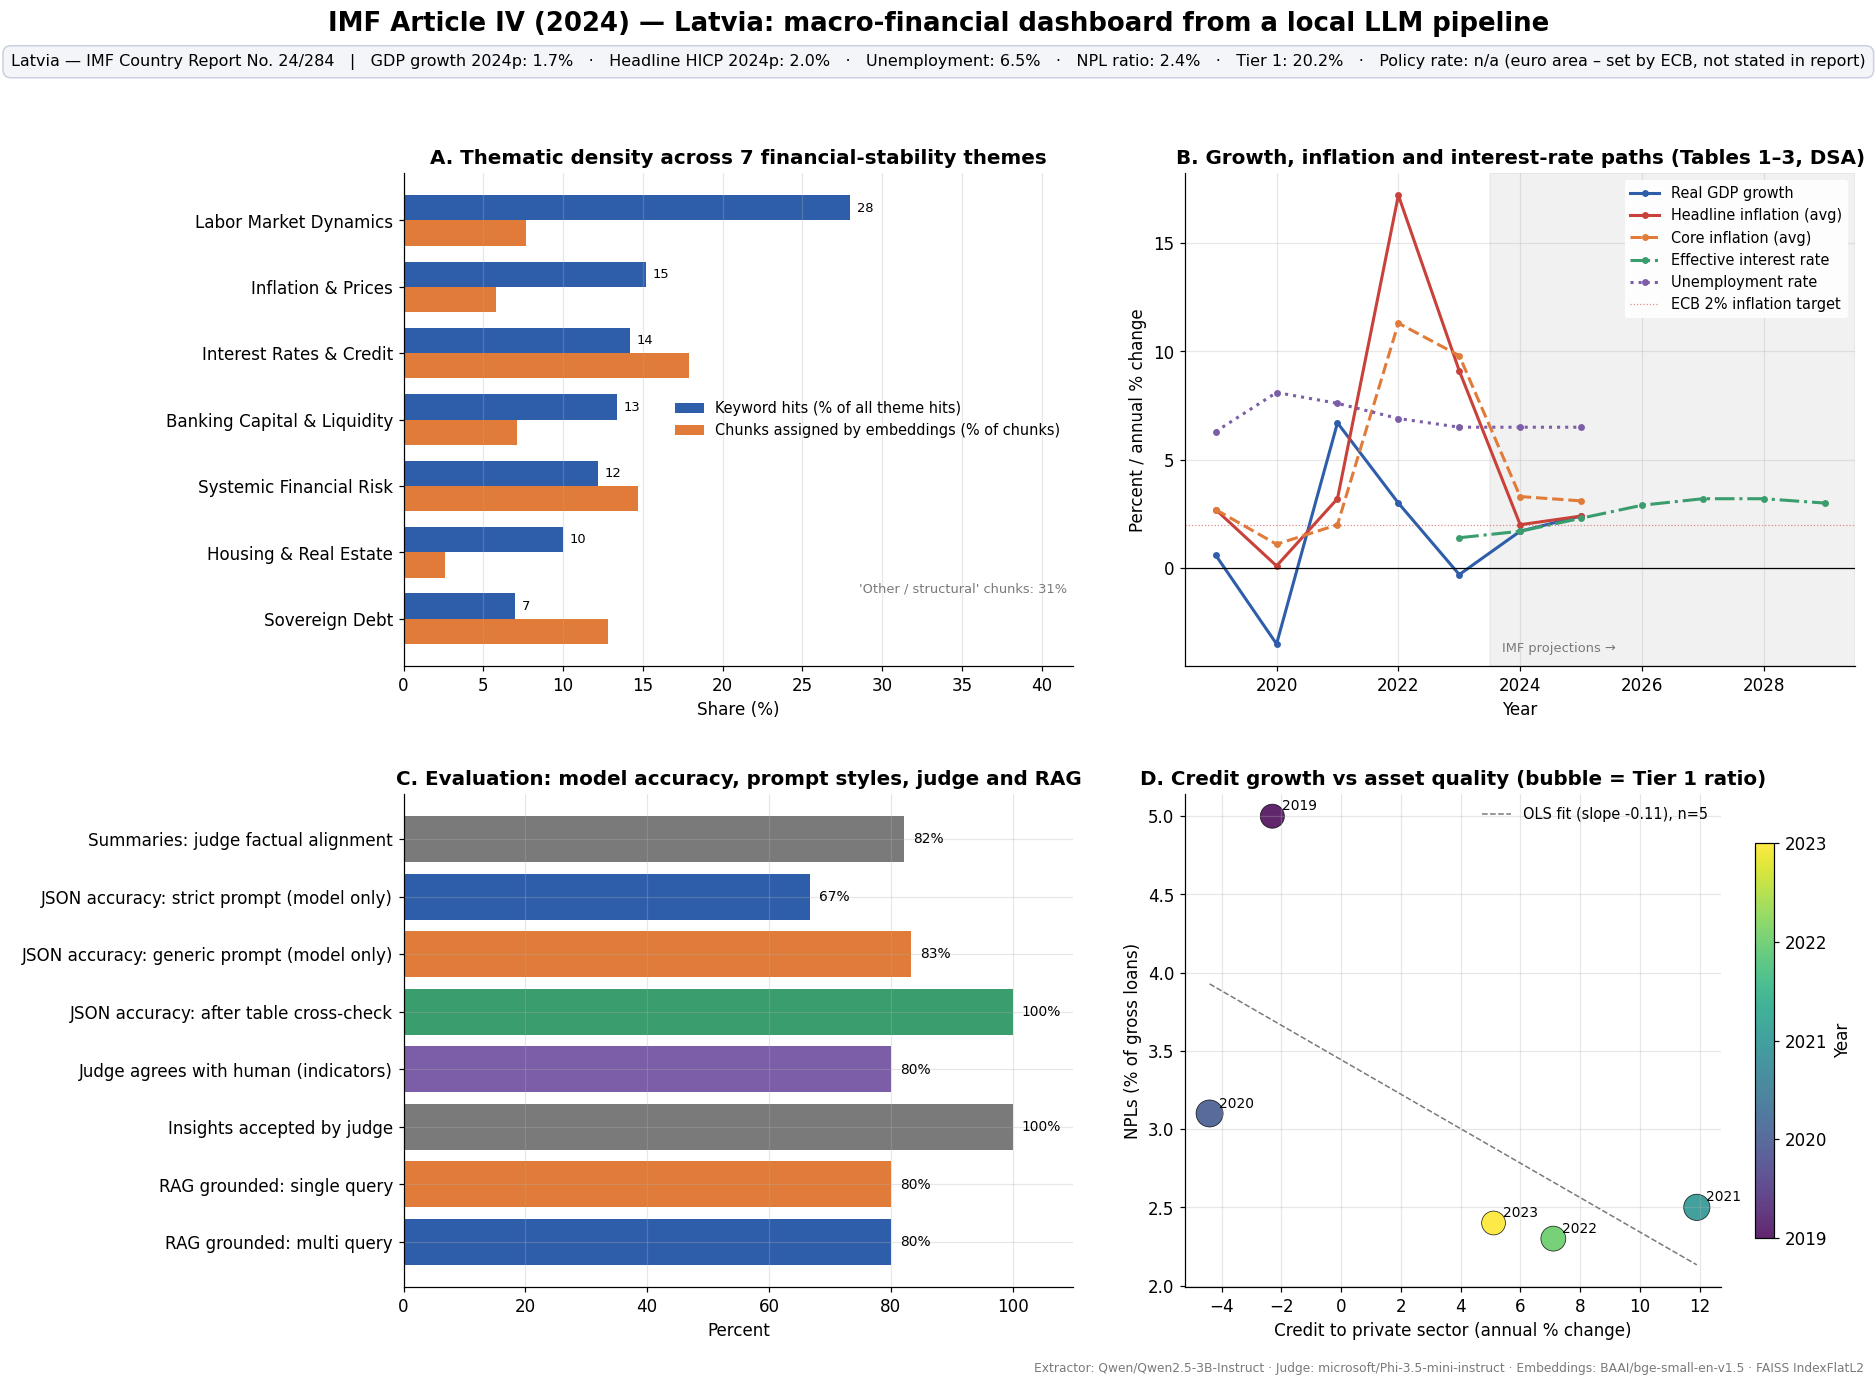

In [26]:
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
                     "legend.fontsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
PALETTE = {"blue": "#2E5EAA", "orange": "#E07B39", "green": "#3A9D6E", "red": "#C8423B", "grey": "#7A7A7A", "purple": "#7B5EA7"}

def fmt_pct(v):
    return "n/a" if v is None or (isinstance(v, float) and math.isnan(v)) else f"{v:.1f}%"

def panel_themes(ax):
    order = theme_df.sort_values("lexical_share_pct").theme.tolist()
    y = np.arange(len(order)); h = 0.38
    lex = theme_long[theme_long.method == "lexical_share_pct"].set_index("theme").loc[order, "share_pct"]
    semv = theme_long[theme_long.method == "semantic_share_pct"].set_index("theme").loc[order, "share_pct"]
    ax.barh(y + h / 2, lex, h, color=PALETTE["blue"], label="Keyword hits (% of all theme hits)")
    ax.barh(y - h / 2, semv, h, color=PALETTE["orange"], label="Chunks assigned by embeddings (% of chunks)")
    for yy, v in zip(y + h / 2, lex): ax.text(v + 0.4, yy, f"{v:.0f}", va="center", fontsize=8.5)
    ax.set_yticks(y, order); ax.set_xlabel("Share (%)"); ax.grid(axis="y", alpha=0)
    ax.set_title("A. Thematic density across 7 financial-stability themes")
    ax.set_xlim(0, max(lex.max(), semv.max()) * 1.5)
    ax.legend(loc="center right", frameon=False)
    ax.text(0.99, 0.02 + 0.13, f"'Other / structural' chunks: {other_share:.0f}%", transform=ax.transAxes, ha="right", fontsize=8.5, color=PALETTE["grey"])

def panel_trends(ax):
    show = [("Real GDP growth", PALETTE["blue"], "-"), ("Headline inflation (avg)", PALETTE["red"], "-"),
            ("Core inflation (avg)", PALETTE["orange"], "--"), ("Effective interest rate", PALETTE["green"], "-."),
            ("Unemployment rate", PALETTE["purple"], ":")]
    plotted, years_used = 0, []
    for name, col, ls in show:
        d = trend_long[(trend_long.series == name) & (trend_long.year <= REPORT_YEAR + 5)].sort_values("year")
        if d.empty: continue
        ax.plot(d.year, d.value, ls, color=col, marker="o", ms=3.5, lw=2, label=name); plotted += 1
        years_used += d.year.tolist()
    if not plotted:
        ax.text(0.5, 0.5, "No time series parsed", ha="center", transform=ax.transAxes); return
    x0, x1 = min(years_used) - 0.5, max(years_used) + 0.5
    ax.axvspan(REPORT_YEAR - 0.5, x1, color=PALETTE["grey"], alpha=0.10)
    ax.text(REPORT_YEAR - 0.3, 0.03, "IMF projections →", transform=ax.get_xaxis_transform(), fontsize=8.5, color=PALETTE["grey"])
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(2, color=PALETTE["red"], lw=0.8, ls=":", alpha=0.6, label="ECB 2% inflation target")
    ax.set_xlim(x0, x1); ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.set_ylabel("Percent / annual % change"); ax.set_xlabel("Year")
    ax.set_title("B. Growth, inflation and interest-rate paths (Tables 1–3, DSA)")
    ax.legend(loc="upper right", frameon=True, framealpha=0.9, edgecolor="none", ncol=1)

def panel_evaluation(ax):
    rows = [("Summaries: judge factual alignment", summary_eval_df.factual_alignment.mean() / 5, PALETTE["grey"]),
            ("JSON accuracy: strict prompt (model only)", indicator_accuracy_model.correct.mean(), PALETTE["blue"]),
            ("JSON accuracy: generic prompt (model only)", indicator_accuracy_generic.correct.mean(), PALETTE["orange"]),
            ("JSON accuracy: after table cross-check", indicator_accuracy.correct.mean(), PALETTE["green"]),
            ("Judge agrees with human (indicators)", indicator_eval_df.judge_agrees_with_human.dropna().astype(float).mean(), PALETTE["purple"]),
            ("Insights accepted by judge", insight_eval_df.supported.mean(), PALETTE["grey"]),
            ("RAG grounded: single query", rag_df[rag_df.setup == "single_query"].grounded_or_abstained.mean(), PALETTE["orange"]),
            ("RAG grounded: multi query", rag_df[rag_df.setup == "multi_query"].grounded_or_abstained.mean(), PALETTE["blue"])]
    names = [r[0] for r in rows][::-1]
    perc = [float(r[1]) * 100 if pd.notna(r[1]) else 0 for r in rows][::-1]
    bars = ax.barh(names, perc, color=[r[2] for r in rows][::-1])
    ax.set_xlim(0, 110); ax.set_xlabel("Percent")
    ax.set_title("C. Evaluation: model accuracy, prompt styles, judge and RAG")
    for bar, val in zip(bars, perc):
        ax.text(val + 1.5, bar.get_y() + bar.get_height()/2, f"{val:.0f}%", va="center", fontsize=9)

def panel_credit_npl(ax):
    need = ["Credit to private sector", "NPL ratio"]
    if not all(n in key_series for n in need):
        ax.text(0.5, 0.5, "Credit or NPL series not found in report tables", ha="center", transform=ax.transAxes); return
    piv = trend_long.pivot_table(index="year", columns="series", values="value")
    d = piv.dropna(subset=need)
    size = d["Tier 1 capital ratio"] * 12 if "Tier 1 capital ratio" in d else 80
    sc = ax.scatter(d["Credit to private sector"], d["NPL ratio"], s=size, c=d.index, cmap="viridis", alpha=0.85, edgecolor="black", lw=0.5)
    for yr, r in d.iterrows(): ax.annotate(str(yr), (r["Credit to private sector"], r["NPL ratio"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
    if len(d) >= 3:
        k, b = np.polyfit(d["Credit to private sector"], d["NPL ratio"], 1)
        xs = np.linspace(d["Credit to private sector"].min(), d["Credit to private sector"].max(), 20)
        ax.plot(xs, k * xs + b, color=PALETTE["grey"], ls="--", lw=1, label=f"OLS fit (slope {k:+.2f}), n={len(d)}")
        ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Credit to private sector (annual % change)"); ax.set_ylabel("NPLs (% of gross loans)")
    ax.set_title("D. Credit growth vs asset quality (bubble = Tier 1 ratio)")
    cb = plt.colorbar(sc, ax=ax, label="Year", shrink=0.8, ticks=list(d.index)); cb.ax.set_yticklabels([str(y) for y in d.index])

fig, axes = plt.subplots(2, 2, figsize=(17, 12.5))
panel_themes(axes[0, 0]); panel_trends(axes[0, 1]); panel_evaluation(axes[1, 0]); panel_credit_npl(axes[1, 1])
ind = indicators
overlay = (f"{COUNTRY} — {REPORT_ID}   |   GDP growth {REPORT_YEAR}p: {fmt_pct(ind['gdp_growth_forecast_pct'])}   ·   "
           f"Headline HICP {REPORT_YEAR}p: {fmt_pct(ind['headline_inflation_rate_pct'])}   ·   Unemployment: {fmt_pct(ind['unemployment_rate_pct'])}   ·   "
           f"NPL ratio: {fmt_pct(ind['non_performing_loan_ratio'])}   ·   Tier 1: {fmt_pct(ind['tier_1_capital_ratio'])}   ·   "
           f"Policy rate: {fmt_pct(ind['central_bank_policy_rate_pct'])}"
           + (" (euro area – set by ECB, not stated in report)" if ind['central_bank_policy_rate_pct'] is None else ""))
fig.suptitle(f"IMF Article IV ({REPORT_YEAR}) — {COUNTRY}: macro-financial dashboard from a local LLM pipeline", fontsize=17, fontweight="bold", y=0.995)
fig.text(0.5, 0.955, overlay, ha="center", fontsize=10.5, bbox=dict(boxstyle="round,pad=0.5", fc="#F3F5F9", ec="#C9D1E0"))
fig.text(0.995, 0.005, f"Extractor: {EXTRACTOR_MODEL} · Judge: {JUDGE_MODEL} · Embeddings: {EMBED_MODEL} · FAISS IndexFlatL2", ha="right", fontsize=8, color=PALETTE["grey"])
fig.tight_layout(rect=[0, 0.015, 1, 0.94], h_pad=3, w_pad=3)
for ext in ("png", "pdf"):
    fig.savefig(FIG_DIR / f"dashboard_latvia.{ext}", dpi=300, bbox_inches="tight")
plt.show()